<a href="https://colab.research.google.com/github/linacaro2001-beep/TFM/blob/main/TFM_Lina_Caro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TFM — Predicción de vulnerabilidad socioeconómica y exclusión financiera en hogares españoles

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8')
import os
import pickle
import geopandas as gpd

1. CARGA DE DATOS

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base = '/content/drive/MyDrive/TFM/datos_2025'

df_hogar = pd.read_csv(f'{base}/ECV_Th_2025/CSV/esudb25h.csv', sep=',', encoding='utf-8')
df_basico = pd.read_csv(f'{base}/ECV_Td_2025/CSV/esudb25d.csv', sep=',', encoding='utf-8')
df_personas = pd.read_csv(f'{base}/ECV_Tr_2025/CSV/esudb25r.csv', sep=',', encoding='utf-8')
df_adultos = pd.read_csv(f'{base}/ECV_Tp_2025/CSV/esudb25p.csv', sep=',', encoding='utf-8', low_memory=False)

/tmp/ipykernel_4556/1684331852.py:3: DtypeWarning: Columns (89,91,93,95,101,103,107,109,126) have mixed types. Specify dtype option on import or set low_memory=False.
  df_hogar = pd.read_csv(f'{base}/ECV_Th_2025/CSV/esudb25h.csv', sep=',', encoding='utf-8')
/tmp/ipykernel_4556/1684331852.py:5: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df_personas = pd.read_csv(f'{base}/ECV_Tr_2025/CSV/esudb25r.csv', sep=',', encoding='utf-8')


In [ ]:
print(f"Fichero H (hogar): {df_hogar.shape}")
print(f"Fichero D (básico): {df_basico.shape}")
print(f"Fichero R (personas): {df_personas.shape}")
print(f"Fichero P (personas adultas): {df_adultos.shape}")

Fichero H (hogar): (29369, 156)
Fichero D (básico): (29369, 9)
Fichero R (personas): (71398, 46)
Fichero P (personas adultas): (60825, 253)


2. EXPLORACIÓN INICIAL

In [ ]:
df_hogar.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29369 entries, 0 to 29368
Columns: 156 entries, HB010 to HEE12_F
dtypes: float64(35), int64(84), object(37)
memory usage: 35.0+ MB


El fichero de hogar tiene 29.369 hogares y no tiene valores nulos.

In [ ]:
df_basico.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29369 entries, 0 to 29368
Data columns (total 9 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   DB010    29369 non-null  int64  
 1   DB020    29369 non-null  object 
 2   DB030    29369 non-null  int64  
 3   DB040    29369 non-null  object 
 4   DB040_F  29369 non-null  int64  
 5   DB090    29369 non-null  float64
 6   DB090_F  29369 non-null  int64  
 7   DB100    29369 non-null  int64  
 8   DB100_F  29369 non-null  int64  
dtypes: float64(1), int64(6), object(2)
memory usage: 2.0+ MB


No hay valores nulos

In [ ]:
df_personas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71398 entries, 0 to 71397
Data columns (total 46 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RB010           71398 non-null  int64  
 1   RB020           71398 non-null  object 
 2   RB030           71398 non-null  int64  
 3   RB050           71398 non-null  float64
 4   RB050_F         71398 non-null  int64  
 5   RB080           71398 non-null  int64  
 6   RB080_F         71398 non-null  int64  
 7   RB081           71398 non-null  int64  
 8   RB081_F         71398 non-null  int64  
 9   RB082           71398 non-null  int64  
 10  RB082_F         71398 non-null  int64  
 11  RB090           71398 non-null  int64  
 12  RB090_F         71398 non-null  int64  
 13  RB200           71398 non-null  object 
 14  RB200_F         71398 non-null  int64  
 15  RB211           71398 non-null  object 
 16  RB211_F         71398 non-null  int64  
 17  RB220           71398 non-null 

No hay valores nulos

In [ ]:
def explorar_dataset(df, nombre):
    print(f"\n{'='*50}")
    print(f"DATASET: {nombre}")
    print(f"{'='*50}")
    print(f"Dimensiones: {df.shape}")
    print(f"\nTipos de variables:\n{df.dtypes.value_counts()}")
    print(f"\nValores nulos:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
    print(f"\nPrimeras filas:")
    display(df.head())

explorar_dataset(df_hogar, "Fichero H — Hogar")
explorar_dataset(df_basico, "Fichero D — Básico hogar")
explorar_dataset(df_personas, "Fichero R — Personas")


DATASET: Fichero H — Hogar
Dimensiones: (29369, 156)

Tipos de variables:
int64      84
object     37
float64    35
Name: count, dtype: int64

Valores nulos:
Series([], dtype: int64)

Primeras filas:


,HB010,HB020,HB030,HB050,HB050_F,HB060,HB060_F,HB070,HB070_F,HB080,HB080_F,HB100,HB100_F,HB120,HB120_F,HY020,HY020_F,HY022,HY022_F,HY023,HY023_F,HY030N,HY030N_F,HY040N,HY040N_F,HY050N,HY050N_F,HY060N,HY060N_F,HY070N,HY070N_F,HY080N,HY080N_F,HY081N,HY081N_F,HY090N,HY090N_F,HY100N,HY100N_F,HY110N,HY110N_F,HY120N,HY120N_F,HY130N,HY130N_F,HY131N,HY131N_F,HY145N,HY145N_F,HY170N,HY170N_F,HY010,HY010_F,HY040G,HY040G_F,HY050G,HY050G_F,HY060G,HY060G_F,HY070G,HY070G_F,HY080G,HY080G_F,HY081G,HY081G_F,HY090G,HY090G_F,HY100G,HY100G_F,HY110G,HY110G_F,HY120G,HY120G_F,HY130G,HY130G_F,HY131G,HY131G_F,HY140G,HY140G_F,HS011,HS011_F,HS021,HS021_F,HS022,HS022_F,HS031,HS031_F,HS040,HS040_F,HS050,HS050_F,HS060,HS060_F,HS090,HS090_F,HS110,HS110_F,HS120,HS120_F,HS150,HS150_F,HD080,HD080_F,HH010,HH010_F,HH021,HH021_F,HH030,HH030_F,HH050,HH050_F,HH060,HH060_F,HH070,HH070_F,HI010,HI010_F,HI020,HI020_F,HI030,HI030_F,HI040,HI040_F,cuotahip,cuotahip_F,HX040,HX060,HX240,vhRentaa,vhRentaAIa,vhPobreza,vhMATDEP,HS200,HS200_F,HS210,HS210_F,HS220,HS220_F,HC006,HC006_F,HC003A,HC003A_F,HEE07,HEE07_F,HEE01,HEE01_F,HEE09,HEE09_F,HEE11,HEE11_F,HEE13,HEE13_F,HEE14,HEE14_F,HEE12,HEE12_F
0,2025,ES,1,4,1,2025,1,101,1,101,1,22,1,1,1,10352.00,21,10352.00,21,64.90,11,6056.83,56,420.0,11,0.0,11,0.0,11,0.0,11,0.0,16,0.0,16,72.9,11,0.00,11,0.0,11,78.00,11,0.0,16,0.0,16,350.00,11,0.0,16,10797.10,25,420.0,15,0.0,15,0.0,15,0.0,15,0.0,16,0.0,16,90.0,15,0.00,11,0.0,15,78.00,11,0.0,16,0.0,16,367.10,25,,-2,3,1,2,1,,-2,1,1,1,1,2,1,3,1,1,1,3,1,,-2,1,1,4,1,1,1,5,1,2,1,,-2,217.48,1,3,1,,-2,9,1,2,1,,-2,1,6,1.0,10352.00,16408.83,1,0,3,1,,-2,2,1,4,1,2,1,,-2,1,1,1,1,1,1,2000,1,,-2,1,1
1,2025,ES,2,3,1,2025,1,201,1,201,1,37,1,2,1,42476.24,51,42476.24,51,42476.24,51,6208.03,56,0.0,11,0.0,11,0.0,11,0.0,11,0.0,16,0.0,16,59.0,11,24.00,11,0.0,11,560.00,11,0.0,16,0.0,16,-550.00,11,0.0,16,51879.58,55,0.0,15,0.0,15,0.0,15,0.0,15,0.0,16,0.0,16,75.0,15,24.00,11,0.0,15,560.00,11,0.0,16,0.0,16,8843.33,55,3,1,3,1,2,1,,-2,1,1,1,1,1,1,1,1,1,1,4,1,,-2,1,1,4,1,2,1,5,1,1,1,,-2,254.48,1,2,1,,-2,,-2,2,1,410,1,2,8,1.5,42476.24,48660.27,0,0,2,1,2,1,3,1,5,1,1,1,,-2,1,1,1,1,1,1,2015,1,,-2,1,1
2,2025,ES,3,6,1,2025,1,301,1,302,1,8,1,2,1,28533.64,21,28533.64,21,1613.34,51,6298.03,56,0.0,11,0.0,11,0.0,11,0.0,11,0.0,16,0.0,16,0.0,11,0.00,11,0.0,11,160.00,11,0.0,16,0.0,16,-1773.34,11,0.0,16,31302.70,25,0.0,15,0.0,15,0.0,15,0.0,15,0.0,16,0.0,16,0.0,15,0.00,11,0.0,15,160.00,11,0.0,16,0.0,16,2609.06,25,,-2,3,1,2,1,,-2,1,1,1,1,1,1,3,1,1,1,4,1,,-2,1,1,4,1,1,1,5,1,1,1,,-2,172.90,1,2,1,,-2,,-2,2,1,,-2,2,7,1.5,28533.64,34831.67,0,0,3,1,2,1,3,1,3,1,1,1,,-2,2,1,1,1,1,1,2007,1,,-2,2,1
3,2025,ES,4,4,1,2025,1,401,1,401,1,15,1,2,1,19457.00,11,18257.00,11,18257.00,11,4840.03,56,0.0,11,0.0,11,0.0,11,1200.0,11,0.0,16,0.0,16,0.0,11,3962.42,11,0.0,11,160.00,11,840.0,16,0.0,16,-420.00,11,0.0,16,24014.73,41,0.0,15,0.0,15,0.0,15,1200.0,15,0.0,16,0.0,16,0.0,15,3962.42,11,0.0,15,160.00,11,840.0,16,0.0,16,3557.73,41,3,1,3,1,2,1,3,1,1,1,1,1,2,1,1,1,2,1,1,1,1,1,2,1,4,1,2,1,4,1,2,1,,-2,596.76,1,2,1,,-2,,-2,2,1,500,1,2,10,1.3,19457.00,20334.60,0,0,3,1,1,1,,-2,,-1,4,1,2,1,1,1,1,1,0,1,,-2,,-2,,-2
4,2025,ES,5,5,1,2025,1,501,1,501,1,10,1,5,1,44050.67,51,37878.97,51,26307.07,51,6255.77,56,0.0,11,0.0,11,0.0,11,0.0,11,0.0,16,0.0,16,0.0,11,2091.95,51,0.0,11,244.33,11,0.0,16,0.0,16,-1725.20,11,1010.0,16,45347.39,25,0.0,15,0.0,15,0.0,15,0.0,15,0.0,16,0.0,16,0.0,15,2091.95,51,0.0,15,244.33,11,0.0,16,0.0,16,1052.37,25,3,1,3,1,2,1,,-2,1,1,1,1,2,1,1,1,3,1,1,1,,-2,1,1,3,1,2,1,5,1,1,1,,-2,560.67,1,2,1,,-2,,-2,3,1,,-2,5,14,2.6,44050.67,48214.49,0,0,3,1,2,1,3,1,3,1,5,1,,-2,1,1,1,1,0,1,,-2,,-2,,-2



DATASET: Fichero D — Básico hogar
Dimensiones: (29369, 9)

Tipos de variables:
int64      6
object     2
float64    1
Name: count, dtype: int64

Valores nulos:
Series([], dtype: int64)

Primeras filas:


,DB010,DB020,DB030,DB040,DB040_F,DB090,DB090_F,DB100,DB100_F
0,2025,ES,1,ES21,1,623.81237,1,3,1
1,2025,ES,2,ES21,1,279.26707,1,3,1
2,2025,ES,3,ES21,1,719.41894,1,3,1
3,2025,ES,4,ES21,1,261.64358,1,3,1
4,2025,ES,5,ES21,1,655.08727,1,3,1



DATASET: Fichero R — Personas
Dimensiones: (71398, 46)

Tipos de variables:
int64      31
object     14
float64     1
Name: count, dtype: int64

Valores nulos:
Series([], dtype: int64)

Primeras filas:


,RB010,RB020,RB030,RB050,RB050_F,RB080,RB080_F,RB081,RB081_F,RB082,RB082_F,RB090,RB090_F,RB200,RB200_F,RB211,RB211_F,RB220,RB220_F,RB230,RB230_F,RB240,RB240_F,RB280,RB280_F,RB290,RB290_F,RL010,RL010_F,RL020,RL020_F,RL030,RL030_F,RL040,RL040_F,RL050,RL050_F,RL060,RL060_F,RL070,RL070_F,vrLOWJOB,vrEU2020,vrMATSOCDEP,vrLOWJOB_nuevo,vrEU2030_nuevo
0,2025,ES,101,623.81237,1,1948,1,76,1,77,1,2,1,1,1,3,1,,-2,,-2,,-2,1,1,1,1,,-2,,-2,,-2,,-2,,-2,,-2,,-2,9,1,0,9,1
1,2025,ES,201,279.26707,1,1973,1,51,1,51,1,1,1,1,1,1,1,,-2,,-2,202,1,1,1,1,1,,-2,,-2,,-2,,-2,,-2,,-2,,-2,0,0,0,0,0
2,2025,ES,202,279.26707,1,1974,1,50,1,50,1,2,1,1,1,1,1,,-2,,-2,201,1,1,1,1,1,,-2,,-2,,-2,,-2,,-2,,-2,,-2,0,0,0,0,0
3,2025,ES,301,719.41894,1,1954,1,70,1,71,1,2,1,1,1,6,1,,-2,,-2,302,1,1,1,1,1,,-2,,-2,,-2,,-2,,-2,,-2,,-2,9,0,0,9,0
4,2025,ES,302,719.41894,1,1950,1,74,1,74,1,1,1,1,1,3,1,,-2,,-2,301,1,1,1,1,1,,-2,,-2,,-2,,-2,,-2,,-2,,-2,9,0,0,9,0


In [ ]:
df_hogar.describe()

,HB010,HB030,HB050,HB050_F,HB060,HB060_F,HB070_F,HB080,HB080_F,HB100_F,HB120,HB120_F,HY020,HY020_F,HY022,HY022_F,HY023,HY023_F,HY030N,HY030N_F,HY040N,HY040N_F,HY050N,HY050N_F,HY060N,HY060N_F,HY070N,HY070N_F,HY080N,HY080N_F,HY081N,HY081N_F,HY090N,HY090N_F,HY100N,HY100N_F,HY110N,HY110N_F,HY120N,HY120N_F,HY130N,HY130N_F,HY131N,HY131N_F,HY145N,HY145N_F,HY170N,HY170N_F,HY010,HY010_F,HY040G,HY040G_F,HY050G,HY050G_F,HY060G,HY060G_F,HY070G,HY070G_F,HY080G,HY080G_F,HY081G,HY081G_F,HY090G,HY090G_F,HY100G,HY100G_F,HY110G,HY110G_F,HY120G,HY120G_F,HY130G,HY130G_F,HY131G,HY131G_F,HY140G,HY140G_F,HS011_F,HS021_F,HS022,HS022_F,HS031_F,HS040_F,HS050_F,HS060_F,HS090_F,HS110_F,HS120_F,HS150_F,HD080_F,HH010_F,HH021,HH021_F,HH030_F,HH050_F,HH060_F,HH070_F,HI010_F,HI020_F,HI030_F,HI040_F,cuotahip_F,HX040,HX240,vhRentaa,vhRentaAIa,vhPobreza,vhMATDEP,HS200_F,HS210_F,HS220_F,HC006_F,HC003A_F,HEE07_F,HEE01_F,HEE09_F,HEE11_F,HEE13_F,HEE14_F,HEE12_F
count,29369.0,29369.000000,29369.000000,29369.0,29369.0,29369.0,29369.000000,2.936900e+04,29369.0,29369.000000,29369.000000,29369.0,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.0,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.0,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.00000,29369.000000,29369.000000,29369.0,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000,29369.000000
mean,2025.0,17607.467398,4.339201,1.0,2025.0,1.0,0.938438,1.760748e+06,1.0,0.935851,2.431067,1.0,39896.349686,21.420852,37312.001015,21.402125,28186.405976,21.343219,6601.951168,56.0,1011.106378,12.734822,154.828095,11.123940,233.243377,11.499166,38.728961,11.125302,173.860027,16.093977,114.494882,16.051755,806.118705,20.813749,606.861223,12.154959,23.545503,11.025878,356.584926,11.019068,285.546826,16.196125,164.655820,16.091253,-72.850511,19.770813,34.750823,16.005448,49942.405317,25.220981,1092.156611,16.734822,155.511094,15.150499,233.277427,15.499166,38.728961,15.125302,173.860027,16.093977,114.494882,16.051755,983.875056,24.813749,606.861223,12.154959,23.669477,15.025878,356.584926,11.019068,285.546826,16.196125,164.655820,16.091253,9403.922722,25.220981,-0.731452,0.978106,1.896966,1.0,-1.196840,0.997004,0.999591,0.998298,0.999047,0.999115,0.996595,-1.269774,0.99891,0.995642,1.856413,1.0,0.993531,0.997957,-1.532534,0.992782,0.996527,-1.537778,-1.667098,0.749191,-1.274133,2.431067,1.654987,39896.349686,45891.439698,0.170282,0.066226,0.912459,0.305867,0.853247,0.889884,0.941912,-1.320406,0.992850,0.996118,0.975689,0.370425,-0.975689,0.383704
std,0.0,10882.627719,1.049135,0.0,0.0,0.0,0.345452,1.088263e+06,0.0,0.352403,1.228751,0.0,27486.611641,4.900252,27564.750203,5.312205,28912.109312,6.597085,3200.329721,0.0,3634.812525,4.377291,1344.039898,2.223154,1526.963822,2.484508,371.009599,2.235298,1177.990994,1.936585,874.256926,1.437916,3772.713495,2.739988,1395.967825,6.698206,305.650988,1.017089,741.916739,0.873139,1312.911082,2.7

In [ ]:
# ============================================================
# MERGE DE FICHEROS
# ============================================================

# Se renombra el ID del fichero de hogares para hacer el merge con el fichero
# de datos básicos de hogar.
df_h = df_hogar.rename(columns={'HB030': 'DB030'})

# Merge fichero H + fichero D por ID de hogar
df = df_h.merge(df_basico[['DB030', 'DB040', 'DB100']],
                on='DB030', how='left')

print(f"Dimensiones tras merge: {df.shape}")
print(f"Filas fichero H:  {df_hogar.shape[0]}")
print(f"Filas tras merge: {df.shape[0]}")
print(f"¿El merge es correcto? {df.shape[0] == df_hogar.shape[0]}")

Dimensiones tras merge: (29369, 158)
Filas fichero H:  29369
Filas tras merge: 29369
¿El merge es correcto? True


3. SELECCIÓN DE VARIABLES RELEVANTES

In [ ]:
# ============================================================
# SELECCIÓN DE VARIABLES RELEVANTES
# ============================================================
# Del amplio conjunto de variables disponibles en los ficheros de la ECV,
# se seleccionan 22 relevantes para el estudio de la vulnerabilidad,
# agrupadas en 5 bloques temáticos. El significado completo de cada
# código numérico (por ejemplo, los 5 valores de HH021 o los 14 de
# HX060) está documentado en el diccionario de variables más abajo.

vars_trabajo = [
    # Identificador y geografía
    'DB030',          # ID único del hogar
    'DB040',          # CCAA
    'DB100',          # grado de urbanización (1=muy poblada, 2=media, 3=poco poblada)

    # Pobreza (indicadores calculados por el INE)
    'vhPobreza',      # hogar en riesgo de pobreza (1=sí)
    'vhMATDEP',       # hogar en carencia material severa (1=sí)
    'vhRentaa',       # renta disponible total del hogar (€)

    # Exclusión financiera
    'HS011',          # retrasos en el pago de hipoteca o alquiler
    'HS021',          # retrasos en el pago de facturas
    'HS031',          # retrasos en el pago de préstamos
    'HS060',          # capacidad para afrontar un gasto imprevisto
    'HS120',          # capacidad para llegar a fin de mes
    'HS150',          # carga financiera de las deudas

    # Privación material
    'HS040',          # puede permitirse una semana de vacaciones al año
    'HS050',          # puede permitirse carne o pescado cada 2 días
    'HH050',          # puede mantener la vivienda a temperatura adecuada
    'HS090',          # tiene ordenador
    'HS110',          # tiene coche

    # Vivienda y composición del hogar
    'HH010',          # tipo de vivienda
    'HH021',          # régimen de tenencia de la vivienda
    'HH030',          # número de habitaciones
    'HB120',          # número de miembros
    'HX060',          # tipo de hogar (composición por edad/sexo/hijos dependientes)
]

df = df[vars_trabajo].copy()
print(f"Dataset de trabajo: {df.shape}")
print(f"\nTipos de variables:\n{df.dtypes}")

Dataset de trabajo: (29369, 22)

Tipos de variables:
DB030          int64
DB040         object
DB100          int64
vhPobreza      int64
vhMATDEP       int64
vhRentaa     float64
HS011         object
HS021         object
HS031         object
HS060         object
HS120         object
HS150         object
HS040         object
HS050         object
HH050         object
HS090         object
HS110         object
HH010         object
HH021          int64
HH030         object
HB120          int64
HX060         object
dtype: object


In [ ]:
# ============================================================
# NOTA: FICHEROS R Y P NO INCORPORADOS AL DATASET
# ============================================================

# El fichero R (personas) y P (adultos) tienen nivel de persona,
# no de hogar. Para este TFM el análisis es a nivel de hogar,
# por lo que el dataset de trabajo es H + D.
#
# Variables del fichero R que podrían enriquecer el análisis
# en futuras versiones:
# - RB080: año de nacimiento (edad del sustentador principal)
# - RB090: sexo
# - RB280: país de nacimiento (origen)
# - RB290: nacionalidad
#
# Estas variables requerirían agregar a nivel de hogar
# (ej: edad del cabeza de familia, % miembros extranjeros)
# lo que añade complejidad fuera del alcance de este TFM.

In [ ]:
# ============================================================
# DICCIONARIO DE VARIABLES — TABLA DE REFERENCIA
# Consultar aquí siempre que aparezca un código en tablas o gráficos.
# El desglose completo de HH010, HH021 y HX060 está en el Anexo B del informe.
# ============================================================

diccionario_variables = pd.DataFrame([
    {"Variable": "DB030", "Descripción": "Identificador único del hogar", "Codificación": "Numérico (uso interno, no predictor)"},
    {"Variable": "DB040", "Descripción": "Comunidad Autónoma", "Codificación": "19 categorías (código NUTS-2)"},
    {"Variable": "DB100", "Descripción": "Grado de urbanización", "Codificación": "1=Ciudad grande, 2=Zona intermedia, 3=Zona rural"},
    {"Variable": "vhPobreza", "Descripción": "Hogar en riesgo de pobreza (excluida del modelo, usada en el target)", "Codificación": "0=No, 1=Sí"},
    {"Variable": "vhMATDEP", "Descripción": "Carencia material severa (excluida del modelo)", "Codificación": "0=No, 1=Sí"},
    {"Variable": "vhRentaa", "Descripción": "Renta disponible del hogar", "Codificación": "Numérica continua (€)"},
    {"Variable": "HS011", "Descripción": "Retrasos hipoteca/alquiler (excluida, usada en el target)", "Codificación": "1=Sí 1 vez, 2=Sí 2+ veces, 3=No"},
    {"Variable": "HS021", "Descripción": "Retrasos en facturas (excluida, usada en el target)", "Codificación": "1=Sí 1 vez, 2=Sí 2+ veces, 3=No"},
    {"Variable": "HS031", "Descripción": "Retrasos en préstamos (excluida, usada en el target)", "Codificación": "1=Sí 1 vez, 2=Sí 2+ veces, 3=No"},
    {"Variable": "HS060", "Descripción": "Capacidad afrontar gastos imprevistos (excluida, usada en el target)", "Codificación": "1=Sí puede, 2=No puede"},
    {"Variable": "HS120", "Descripción": "Capacidad de llegar a fin de mes (excluida, usada en el target)", "Codificación": "Escala 1 (mucha dificultad) a 6 (mucha facilidad)"},
    {"Variable": "HS150", "Descripción": "Carga financiera de deudas", "Codificación": "1=Pesada, 2=Razonable, 3=Ninguna"},
    {"Variable": "HS040", "Descripción": "Puede permitirse vacaciones", "Codificación": "1=Sí, 2=No"},
    {"Variable": "HS050", "Descripción": "Puede permitirse proteína cada 2 días", "Codificación": "1=Sí, 2=No"},
    {"Variable": "HH050", "Descripción": "Puede mantener temperatura adecuada", "Codificación": "1=Sí, 2=No"},
    {"Variable": "HS090", "Descripción": "Dispone de ordenador", "Codificación": "1=Sí, 2=No (no puede permitírselo), 3=No (otro motivo)"},
    {"Variable": "HS110", "Descripción": "Dispone de vehículo", "Codificación": "1=Sí, 2=No (no puede permitírselo), 3=No (otro motivo)"},
    {"Variable": "HH010", "Descripción": "Tipo de vivienda", "Codificación": "4 categorías (ver Anexo B)"},
    {"Variable": "HH021", "Descripción": "Régimen de tenencia", "Codificación": "5 categorías (ver Anexo B)"},
    {"Variable": "HH030", "Descripción": "Número de habitaciones", "Codificación": "Numérica discreta"},
    {"Variable": "HB120", "Descripción": "Número de miembros del hogar", "Codificación": "Numérica discreta"},
    {"Variable": "HX060", "Descripción": "Tipo de hogar (composición)", "Codificación": "14 categorías (ver Anexo B)"},
])

print(f"Total de variables documentadas: {len(diccionario_variables)}")
diccionario_variables

Total de variables documentadas: 22


,Variable,Descripción,Codificación
0,DB030,Identificador único del hogar,"Numérico (uso interno, no predictor)"
1,DB040,Comunidad Autónoma,19 categorías (código NUTS-2)
2,DB100,Grado de urbanización,"1=Ciudad grande, 2=Zona intermedia, 3=Zona rural"
3,vhPobreza,Hogar en riesgo de pobreza (excluida del model...,"0=No, 1=Sí"
4,vhMATDEP,Carencia material severa (excluida del modelo),"0=No, 1=Sí"
5,vhRentaa,Renta disponible del hogar,Numérica continua (€)
6,HS011,"Retrasos hipoteca/alquiler (excluida, usada en...","1=Sí 1 vez, 2=Sí 2+ veces, 3=No"
7,HS021,"Retrasos en facturas (excluida, usada en el ta...","1=Sí 1 vez, 2=Sí 2+ veces, 3=No"
8,HS031,"Retrasos en préstamos (excluida, usada en el t...","1=Sí 1 vez, 2=Sí 2+ veces, 3=No"
9,HS060,Capacidad afrontar gastos imprevistos (excluid...,"1=Sí puede, 2=No puede"


In [ ]:
# ============================================================
# ANÁLISIS DE CÓDIGOS ESPECIALES INE
# El diseño de registro de la ECV contempla los códigos -2
# ("no aplicable") y -1 ("no consta") para estas variables, pero
# van en una columna aparte (por ejemplo,HS011_F), no en la
# variable en sí. Como el dataset de trabajo no incluye esas
# columnas de indicador, se comprueba aquí si, aun así, alguno de
# esos códigos se han colado en los valores de las variables principales.
# ============================================================

print("FRECUENCIA DE CÓDIGOS ESPECIALES POR VARIABLE")
print("="*55)

vars_categoricas = ['HS011','HS021','HS031','HS040','HS050',
                    'HS060','HS090','HS110','HS120','HS150',
                    'HH010','HH021','HH050','HX060','DB100',
                    'vhPobreza','vhMATDEP']

for var in vars_categoricas:
    if var in df.columns:
        # Primero vemos qué tipo de datos tiene la variable
        tipo = df[var].dtype
        valores_unicos = df[var].unique()

        print(f"\n{var} (dtype: {tipo}):")
        print(f"  Valores únicos: {sorted(valores_unicos, key=str)}")

        # Buscamos códigos especiales como int o como string
        for codigo in [-2, -1, '-2', '-1']:
            freq = (df[var] == codigo).sum()
            if freq > 0:
                significado = "no aplicable" if codigo in [-2, '-2'] else "no sabe/no contesta"
                print(f"Código {codigo} ({significado}): {freq} ({freq/len(df)*100:.1f}%)")

        # Si no hay códigos especiales
        tiene_especiales = any((df[var] == c).sum() > 0
                               for c in [-2, -1, '-2', '-1'])
        if not tiene_especiales:
            print(f"Sin códigos especiales")

FRECUENCIA DE CÓDIGOS ESPECIALES POR VARIABLE

HS011 (dtype: object):
  Valores únicos: [' ', '1', '2', '3']
Sin códigos especiales

HS021 (dtype: object):
  Valores únicos: [' ', '1', '2', '3']
Sin códigos especiales

HS031 (dtype: object):
  Valores únicos: [' ', '1', '2', '3']
Sin códigos especiales

HS040 (dtype: object):
  Valores únicos: [' ', '1', '2']
Sin códigos especiales

HS050 (dtype: object):
  Valores únicos: [' ', '1', 1, '2', 2]
Sin códigos especiales

HS060 (dtype: object):
  Valores únicos: [' ', 1, '1', 2, '2']
Sin códigos especiales

HS090 (dtype: object):
  Valores únicos: [' ', '1', 1, '2', 2, '3', 3]
Sin códigos especiales

HS110 (dtype: object):
  Valores únicos: [' ', '1', 1, '2', 2, '3', 3]
Sin códigos especiales

HS120 (dtype: object):
  Valores únicos: [' ', '1', '2', '3', '4', '5', '6']
Sin códigos especiales

HS150 (dtype: object):
  Valores únicos: [' ', '1', '2', '3']
Sin códigos especiales

HH010 (dtype: object):
  Valores únicos: [' ', '1', 1, '2', 2, 

In [ ]:
# ============================================================
# VERIFICACIÓN DE DUPLICADOS
# ============================================================

print(f"Filas totales en el dataset: {len(df)}")
print(f"Filas completamente duplicadas: {df.duplicated().sum()}")
print(f"Hogares con DB030 (ID) duplicado: {df['DB030'].duplicated().sum()}")

Filas totales en el dataset: 29369
Filas completamente duplicadas: 0
Hogares con DB030 (ID) duplicado: 0


Hay espacios en blanco (''), en vez de ser NaN. Estos valores se consideran missings.

Se comprobó que no existen duplicados: ni filas completas repetidas ni identificadores de hogar (DB030) duplicados.

Hay problemas con la tipología de las variables: varias llegan como tipo "object" en vez de numéricas, y hay que convertirlas antes de poder trabajar con ellas.

3.2. MISSINGS IDENTIFICADOS

In [ ]:
# ============================================================
# CUANTIFICACIÓN DE MISSINGS REALES (espacios en blanco)
# ============================================================

print("ANÁLISIS DE ESPACIOS EN BLANCO (' ') POR VARIABLE")
print("="*55)

vars_object = [col for col in df.select_dtypes(include='object').columns
               if col in vars_trabajo]

resumen_blancos = []
for var in vars_object:
    n_blancos = (df[var] == ' ').sum()
    pct = n_blancos / len(df) * 100
    resumen_blancos.append({'variable': var,
                            'n_blancos': n_blancos,
                            'pct': round(pct, 1)})
    estado = "MISSING" if n_blancos > 0 else "NO HAY MISSING"
    print(f"{estado} {var}: {n_blancos} blancos ({pct:.1f}%)")

print(f"\nTotal variables con blancos: {sum(1 for r in resumen_blancos if r['n_blancos'] > 0)}")

ANÁLISIS DE ESPACIOS EN BLANCO (' ') POR VARIABLE
NO HAY MISSING DB040: 0 blancos (0.0%)
MISSING HS011: 16983 blancos (57.8%)
MISSING HS021: 237 blancos (0.8%)
MISSING HS031: 21514 blancos (73.3%)
MISSING HS060: 25 blancos (0.1%)
MISSING HS120: 50 blancos (0.2%)
MISSING HS150: 22247 blancos (75.7%)
MISSING HS040: 44 blancos (0.1%)
MISSING HS050: 6 blancos (0.0%)
MISSING HH050: 30 blancos (0.1%)
MISSING HS090: 14 blancos (0.0%)
MISSING HS110: 13 blancos (0.0%)
MISSING HH010: 64 blancos (0.2%)
MISSING HH030: 95 blancos (0.3%)
MISSING HX060: 57 blancos (0.2%)

Total variables con blancos: 14


In [ ]:
# ============================================================
# LIMPIEZA COMPLETA DEL DATASET
# ============================================================

df_limpio = df.copy()

# -- PASO 1: Convertir espacios en blanco a NaN --
for var in vars_object:
    df_limpio[var] = df_limpio[var].replace(' ', np.nan)

print("Paso 1 completado: espacios → NaN")

# -- PASO 2: Unificar tipos mixtos (int + string) --
# Convertimos todo a string primero, luego a numérico
vars_a_convertir = ['HS011','HS021','HS031','HS040','HS050',
                    'HS060','HS090','HS110','HS120','HS150',
                    'HH010','HH050','HX060']

for var in vars_a_convertir:
    if var in df_limpio.columns:
        df_limpio[var] = pd.to_numeric(df_limpio[var], errors='coerce')

print("Paso 2 completado: tipos mixtos unificados a numérico")

# -- PASO 3: Verificar resultado --
print("\nTIPOS TRAS LIMPIEZA:")
print(df_limpio[vars_trabajo].dtypes)

Paso 1 completado: espacios → NaN
Paso 2 completado: tipos mixtos unificados a numérico

TIPOS TRAS LIMPIEZA:
DB030          int64
DB040         object
DB100          int64
vhPobreza      int64
vhMATDEP       int64
vhRentaa     float64
HS011        float64
HS021        float64
HS031        float64
HS060        float64
HS120        float64
HS150        float64
HS040        float64
HS050        float64
HH050        float64
HS090        float64
HS110        float64
HH010        float64
HH021          int64
HH030         object
HB120          int64
HX060        float64
dtype: object


In [ ]:
# ============================================================
# ANÁLISIS DE MISSINGS TRAS LIMPIEZA
# ============================================================

missings = df_limpio.isnull().sum()
missings_pct = (missings / len(df_limpio) * 100).round(1)

resumen = pd.DataFrame({
    'n_missing': missings,
    'pct_missing': missings_pct
}).query('n_missing > 0').sort_values('pct_missing', ascending=False)

print("MISSINGS REALES TRAS LIMPIEZA")
print("="*55)

if len(resumen) == 0:
    print("No hay missings")
else:
    print(resumen)
    print(f"\nTotal variables con missings: {len(resumen)}")

    # Clasificación por gravedad
    print("\nCLASIFICACIÓN POR GRAVEDAD:")
    print("🔴 Críticos (>20%):")
    print(resumen[resumen['pct_missing'] > 20])
    print("\n🟡 Moderados (5-20%):")
    print(resumen[(resumen['pct_missing'] >= 5) & (resumen['pct_missing'] <= 20)])
    print("\n🟢 Leves (<5%):")
    print(resumen[resumen['pct_missing'] < 5])

MISSINGS REALES TRAS LIMPIEZA
       n_missing  pct_missing
HS150      22247         75.7
HS031      21514         73.3
HS011      16983         57.8
HS021        237          0.8
HH030         95          0.3
HS120         50          0.2
HX060         57          0.2
HH010         64          0.2
HS060         25          0.1
HS040         44          0.1
HH050         30          0.1
HS050          6          0.0
HS090         14          0.0
HS110         13          0.0

Total variables con missings: 14

CLASIFICACIÓN POR GRAVEDAD:
🔴 Críticos (>20%):
       n_missing  pct_missing
HS150      22247         75.7
HS031      21514         73.3
HS011      16983         57.8

🟡 Moderados (5-20%):
Empty DataFrame
Columns: [n_missing, pct_missing]
Index: []

🟢 Leves (<5%):
       n_missing  pct_missing
HS021        237          0.8
HH030         95          0.3
HS120         50          0.2
HX060         57          0.2
HH010         64          0.2
HS060         25          0.1
HS040     

¿Por que hay tantos missings en HS150, HS031 Y HS011?

HS011 (57.8%), HS031 (73.3%), HS150 (75.7%) — missings críticos
Estos no son errores aleatorios. Consultando el diseño de registro del INE, estos valores en blancos corresponden a hogares a los que la pregunta no aplica:

HS011 —> retrasos en hipoteca/alquiler → no aplica a hogares sin hipoteca ni alquiler (propietarios sin deuda)
HS031 —> retrasos en préstamos → no aplica a hogares sin préstamos
HS150 —> carga financiera de deudas → no aplica a hogares sin deudas

Es decir, el blanco no significa "no sabe" sino "no tiene hipoteca/préstamo/deuda". Esto cambia completamente la estrategia de tratamiento del dato.

In [ ]:
# ============================================================
# VERIFICACIÓN: ¿Los missings de HS011, HS031, HS150
# corresponden a hogares sin deudas/hipoteca/alquiler?
# ============================================================

print("ANÁLISIS DE MISSINGS CRÍTICOS")
print("="*55)

# HH021 = régimen de tenencia
# 1=propietario sin hipoteca, 2=propietario con hipoteca
# 3=alquiler precio mercado, 4=alquiler precio inferior al de mercado, 5=cesión gratuita

print("\nHS011 (retrasos hipoteca/alquiler) — missings por régimen de tenencia:")
print(pd.crosstab(
    df_limpio['HH021'],
    df_limpio['HS011'].isna(),
    rownames=['HH021'],
    colnames=['HS011 es NaN']
))

print("\nHS031 (retrasos préstamos) — distribución de missings:")
print(f"Total missings HS031: {df_limpio['HS031'].isna().sum()}")
print(f"Total missings HS011: {df_limpio['HS011'].isna().sum()}")
print(f"¿Coinciden los missings de HS011 y HS031?")
coinciden = (df_limpio['HS011'].isna() == df_limpio['HS031'].isna()).sum()
print(f"Filas donde coinciden: {coinciden} de {len(df_limpio)}")

print("\nHS150 (carga financiera deudas) — missings:")
print(f"Total missings HS150: {df_limpio['HS150'].isna().sum()}")

ANÁLISIS DE MISSINGS CRÍTICOS

HS011 (retrasos hipoteca/alquiler) — missings por régimen de tenencia:
HS011 es NaN  False  True 
HH021                     
1               121  15108
2              7646     30
3              3712     21
4               907      7
5                 0   1817

HS031 (retrasos préstamos) — distribución de missings:
Total missings HS031: 21514
Total missings HS011: 16983
¿Coinciden los missings de HS011 y HS031?
Filas donde coinciden: 18458 de 29369

HS150 (carga financiera deudas) — missings:
Total missings HS150: 22247


HS011 — Retrasos hipoteca/alquiler:

HH021=1 (propietarios SIN hipoteca): 15.108 missings de 15.229 → 99% tiene sentido, porque no hay ninguna hipoteca ni alquiler sobre el
que declarar retrasos. Y en HH021=5 (cesión gratuita), el patrón es aún más claro:
el 100% de los hogares tiene el valor en blanco, ya que quien no paga nada por su vivienda no puede tener "retrasos" en un pago inexistente.

En cambio, en los hogares donde SI hay un pago (HH021=2, 3 y 4: hipoteca o alquiler), los missings son casi inexistentes (30, 21 y 7 hogares respectivamente).

Los totales de missings (16.983 en HS011, 21.514 en HS031, 22.247 en HS150) coinciden exactamente con los porcentajes calculados antes (57,8%, 73,3% y 75,7%), confirmando que el análisis es coherente.

En cuanto a si los missings de HS011 y HS031 coinciden entre sí, solo lo hacen en el 62,8% de los hogares (18.458 de 29.369) — y esto es esperable, no un problema: HS011 trata sobre la vivienda principal y HS031 sobre otro tipo de préstamos, así que un hogar puede tener hipoteca pero no otras deudas, o viceversa. No tienen por qué moverse juntos.

Conclusión: el missing en HS011 significa "no tiene hipoteca ni alquiler" → imputamos estos casos con el código 3 (= "No", no ha habido retrasos, porque no hay nada que pagar)

In [ ]:
# Verificación específica para HS031 y HS150 (ambas sobre "otros préstamos")
print("¿Coinciden los missings de HS031 y HS150?")
coinciden_031_150 = (df_limpio['HS031'].isna() == df_limpio['HS150'].isna()).sum()
print(f"Filas donde coinciden: {coinciden_031_150} de {len(df_limpio)} ({coinciden_031_150/len(df_limpio)*100:.1f}%)")

¿Coinciden los missings de HS031 y HS150?
Filas donde coinciden: 25870 de 29369 (88.1%)


Para HS031 y HS150, ambas relacionadas con "otros préstamos" (no relacionados con la vivienda), se comprobó si sus missings coinciden entre sí: coinciden en el 88,1% de los hogares (25.870 de 29.369). Esta coincidencia tan alta confirma que ambos missings corresponden mayoritariamente a la misma causa --> no tener este tipo de deuda.

3.3 TRATAMIENTO DE MISSINGS CRÍTICOS (>20%)

In [ ]:
# ============================================================
# TRATAMIENTO DE MISSINGS CRÍTICOS
# HS011, HS031, HS150 → "no aplica" = ausencia del problema
# ============================================================

df_limpio2 = df_limpio.copy()

# HS011: missing = sin hipoteca/alquiler → no ha habido retrasos → código 3 ("No")
df_limpio2['HS011'] = df_limpio2['HS011'].fillna(3)

# HS031: missing = sin préstamos → no ha habido retrasos → código 3 ("No")
df_limpio2['HS031'] = df_limpio2['HS031'].fillna(3)

# HS150: missing = sin deudas → ninguna carga financiera → código 3 ("Ninguna carga")
df_limpio2['HS150'] = df_limpio2['HS150'].fillna(3)

print("✅ Missings críticos tratados (codificación verificada contra el diccionario oficial):")
print(f"  HS011: {df_limpio2['HS011'].isna().sum()} missings restantes")
print(f"  HS031: {df_limpio2['HS031'].isna().sum()} missings restantes")
print(f"  HS150: {df_limpio2['HS150'].isna().sum()} missings restantes")

✅ Missings críticos tratados (codificación verificada contra el diccionario oficial):
  HS011: 0 missings restantes
  HS031: 0 missings restantes
  HS150: 0 missings restantes



3.4. TRATAMIENTO DE MISSINGS LEVES (<1%)

In [ ]:
# ============================================================
# TRATAMIENTO DE MISSINGS LEVES (<5%)
# ============================================================

# Variables con missings leves — usamos la MODA
# porque son variables categóricas ordinales
vars_moda = ['HS021', 'HS060', 'HS120', 'HS040',
             'HS050', 'HH050', 'HS090', 'HS110',
             'HH010', 'HX060']

print("IMPUTACIÓN POR MODA — VARIABLES LEVES")
print("="*55)

for var in vars_moda:
    if var in df_limpio2.columns:
        n_antes = df_limpio2[var].isna().sum()
        if n_antes > 0:
            moda = df_limpio2[var].mode()[0]
            df_limpio2[var] = df_limpio2[var].fillna(moda)
            print(f"✅ {var}: {n_antes} missings → imputados con moda={moda}")

# HH030 es numérica → usamos mediana
n_antes = df_limpio2['HH030'].isna().sum()
if n_antes > 0:
    # Primero convertimos HH030 a numérica (salió como object)
    df_limpio2['HH030'] = pd.to_numeric(df_limpio2['HH030'], errors='coerce')
    mediana = df_limpio2['HH030'].median()
    df_limpio2['HH030'] = df_limpio2['HH030'].fillna(mediana)
    print(f"✅ HH030: {n_antes} missings → imputados con mediana={mediana}")

IMPUTACIÓN POR MODA — VARIABLES LEVES
✅ HS021: 237 missings → imputados con moda=3.0
✅ HS060: 25 missings → imputados con moda=1.0
✅ HS120: 50 missings → imputados con moda=4.0
✅ HS040: 44 missings → imputados con moda=1.0
✅ HS050: 6 missings → imputados con moda=1.0
✅ HH050: 30 missings → imputados con moda=1.0
✅ HS090: 14 missings → imputados con moda=1.0
✅ HS110: 13 missings → imputados con moda=1.0
✅ HH010: 64 missings → imputados con moda=4.0
✅ HX060: 57 missings → imputados con moda=7.0
✅ HH030: 95 missings → imputados con mediana=5.0


3.5. RESULTADO FINAL

In [ ]:
# ============================================================
# VERIFICACIÓN FINAL — SIN MISSINGS
# ============================================================

missings_final = df_limpio2.isnull().sum()
missings_con_valores = missings_final[missings_final > 0]

if len(missings_con_valores) == 0:
    print("✅ Dataset limpio: 0 missings en todas las variables")
else:
    print("⚠️ Aún quedan missings:")
    print(missings_con_valores)

print(f"\nDimensiones finales: {df_limpio2.shape}")
print(f"Registros: {len(df_limpio2)}")

✅ Dataset limpio: 0 missings en todas las variables

Dimensiones finales: (29369, 22)
Registros: 29369


In [ ]:
# ============================================================
# VERIFICACIÓN FORMAL DE TIPOS DE VARIABLES
# ============================================================

print("CLASIFICACIÓN ESPERADA VS REAL DE VARIABLES")
print("="*55)

# Definimos qué tipo debería tener cada variable
clasificacion_esperada = {
    # Identificadores — no se usan en modelos
    'DB030':    ('identificador', 'int64'),

    # Geográficas — categóricas nominales
    'DB040':    ('categórica nominal', 'object'),   # CCAA (ES21, ES11...)
    'DB100':    ('categórica ordinal', 'int64'),     # 1=ciudad, 2=intermedio, 3=rural

    # Variables derivadas INE — binarias
    'vhPobreza': ('binaria', 'int64'),               # 0/1
    'vhMATDEP':  ('binaria', 'int64'),               # 0/1

    # Continua
    'vhRentaa':  ('numérica continua', 'float64'),

    # Exclusión financiera — categóricas ordinales
    'HS011':    ('categórica ordinal', 'float64'),   # 1=sí 1 vez, 2=sí 2+ veces, 3=no
    'HS021':    ('categórica ordinal', 'float64'),   # 1=sí 1 vez, 2=sí 2+ veces, 3=no
    'HS031':    ('categórica ordinal', 'float64'),   # 1=sí 1 vez, 2=sí 2+ veces, 3=no
    'HS060':    ('categórica ordinal', 'float64'),   # 1=sí, 2=no
    'HS120':    ('categórica ordinal', 'float64'),   # escala 1-6
    'HS150':    ('categórica ordinal', 'float64'),   # escala 1-4

    # Privación material — categóricas binarias
    'HS040':    ('categórica ordinal', 'float64'),   # 1=sí, 2=no
    'HS050':    ('categórica ordinal', 'float64'),   # 1=sí, 2=no
    'HH050':    ('categórica ordinal', 'float64'),   # 1=sí, 2=no
    'HS090':    ('categórica ordinal', 'float64'),   # 1=sí, 2=no (por no poder permitírselo), 3=no (otro motivo)
    'HS110':    ('categórica ordinal', 'float64'),   # 1=sí, 2=no (por no poder permitírselo), 3=no (otro motivo)

    # Vivienda — categóricas nominales/ordinales
    'HH010':    ('categórica nominal', 'float64'),   # tipo vivienda 1-4
    'HH021':    ('categórica nominal', 'int64'),     # tenencia 1-5
    'HH030':    ('numérica discreta', 'float64'),    # nº habitaciones

    # Composición hogar — numéricas discretas
    'HB120':    ('numérica discreta', 'int64'),      # nº miembros
    'HX060':    ('categórica nominal', 'float64'),   # tipo de hogar
}

print(f"\n{'Variable':<12} {'Clasificación':<25} {'Tipo esperado':<15} {'Tipo real':<15} {'Estado'}")
print("-"*85)

problemas = []
for var, (clasificacion, tipo_esperado) in clasificacion_esperada.items():
    if var in df_limpio2.columns:
        tipo_real = str(df_limpio2[var].dtype)
        ok = "✅" if tipo_real == tipo_esperado else "⚠️"
        if tipo_real != tipo_esperado:
            problemas.append(var)
        print(f"{var:<12} {clasificacion:<25} {tipo_esperado:<15} {tipo_real:<15} {ok}")

print(f"\nVariables con tipo incorrecto: {len(problemas)}")
if problemas:
    print(f"Variables a corregir: {problemas}")

CLASIFICACIÓN ESPERADA VS REAL DE VARIABLES

Variable     Clasificación             Tipo esperado   Tipo real       Estado
-------------------------------------------------------------------------------------
DB030        identificador             int64           int64           ✅
DB040        categórica nominal        object          object          ✅
DB100        categórica ordinal        int64           int64           ✅
vhPobreza    binaria                   int64           int64           ✅
vhMATDEP     binaria                   int64           int64           ✅
vhRentaa     numérica continua         float64         float64         ✅
HS011        categórica ordinal        float64         float64         ✅
HS021        categórica ordinal        float64         float64         ✅
HS031        categórica ordinal        float64         float64         ✅
HS060        categórica ordinal        float64         float64         ✅
HS120        categórica ordinal        float64         float6

In [ ]:
# ============================================================
#  VERIFICACIÓN DE TIPOS DE VARIABLES
# ============================================================

print("VERIFICACIÓN DE TIPOS")
print("="*55)

# Variables que deberían ser numéricas
vars_continuas = ['vhRentaa']
vars_discretas = ['HH030', 'HB120']

# Variables que deberían ser categóricas (factor)
vars_categoricas_esperadas = [
    'vhPobreza', 'vhMATDEP', 'HS011', 'HS021', 'HS031',
    'HS040', 'HS050', 'HS060', 'HS090', 'HS110', 'HS120',
    'HS150', 'HH010', 'HH021', 'HH050', 'HX060', 'DB100'
]

print("\nVariables continuas:")
for var in vars_continuas:
    if var in df_limpio2.columns:
        print(f"  {var}: {df_limpio2[var].dtype} ✅"
              if df_limpio2[var].dtype in ['int64','float64']
              else f"  {var}: {df_limpio2[var].dtype} ⚠️ revisar")

print("\nVariables discretas:")
for var in vars_discretas:
    if var in df_limpio2.columns:
        print(f"  {var}: {df_limpio2[var].dtype} ✅"
              if df_limpio2[var].dtype in ['int64', 'float64']
              else f"  {var}: {df_limpio2[var].dtype} ⚠️ revisar")

print("\nVariables categóricas:")
for var in vars_categoricas_esperadas:
    if var in df_limpio2.columns:
        n_unique = df_limpio2[var].nunique()
        print(f"  {var}: {df_limpio2[var].dtype} — {n_unique} categorías únicas")

VERIFICACIÓN DE TIPOS

Variables continuas:
  vhRentaa: float64 ✅

Variables discretas:
  HH030: float64 ✅
  HB120: int64 ✅

Variables categóricas:
  vhPobreza: int64 — 2 categorías únicas
  vhMATDEP: int64 — 2 categorías únicas
  HS011: float64 — 3 categorías únicas
  HS021: float64 — 3 categorías únicas
  HS031: float64 — 3 categorías únicas
  HS040: float64 — 2 categorías únicas
  HS050: float64 — 2 categorías únicas
  HS060: float64 — 2 categorías únicas
  HS090: float64 — 3 categorías únicas
  HS110: float64 — 3 categorías únicas
  HS120: float64 — 6 categorías únicas
  HS150: float64 — 3 categorías únicas
  HH010: float64 — 4 categorías únicas
  HH021: int64 — 5 categorías únicas
  HH050: float64 — 2 categorías únicas
  HX060: float64 — 14 categorías únicas
  DB100: int64 — 3 categorías únicas


In [ ]:
# ============================================================
# CATEGORÍAS MINORITARIAS (<2%) — RESUMEN
# ============================================================
print("CATEGORÍAS CON PRESENCIA MINORITARIA (<2% de la muestra)")
print("="*55)

for var in vars_categoricas_esperadas:
    if var in df_limpio2.columns:
        dist = df_limpio2[var].value_counts(normalize=True) * 100
        minoritarias = dist[dist < 2]
        if len(minoritarias) > 0:
            print(f"\n{var}:")
            for cat, pct in minoritarias.items():
                print(f"  {cat}: {pct:.1f}%")

CATEGORÍAS CON PRESENCIA MINORITARIA (<2% de la muestra)

HS011:
  1.0: 1.3%

HS031:
  1.0: 1.2%

HX060:
  1.0: 0.5%
  4.0: 0.4%


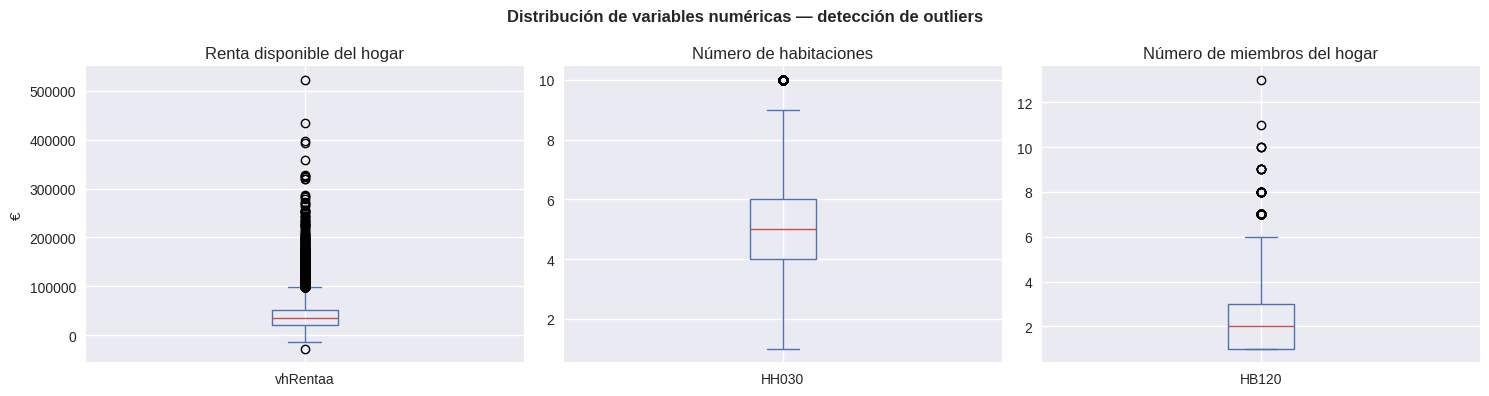


ESTADÍSTICOS DESCRIPTIVOS — VARIABLES NUMÉRICAS
            vhRentaa         HH030         HB120
count   29369.000000  29369.000000  29369.000000
mean    39896.349686      4.875958      2.431067
std     27486.611641      1.520126      1.228751
min    -28024.300000      1.000000      1.000000
25%     21033.990000      4.000000      1.000000
50%     34733.500000      5.000000      2.000000
75%     51693.900000      6.000000      3.000000
max    522875.200000     10.000000     13.000000

DETECCIÓN DE OUTLIERS (método IQR)

vhRentaa:
  Rango normal: [-24956, 97684]
  Outliers detectados: 1026 (3.5%)

HH030:
  Rango normal: [1, 9]
  Outliers detectados: 362 (1.2%)

HB120:
  Rango normal: [-2, 6]
  Outliers detectados: 95 (0.3%)


In [ ]:
# ============================================================
# OUTLIERS EN VARIABLES CONTINUAS Y DISCRETAS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Distribución de variables numéricas — detección de outliers',
             fontsize=12, fontweight='bold')

df_limpio2['vhRentaa'].plot(kind='box', ax=axes[0])
axes[0].set_title('Renta disponible del hogar')
axes[0].set_ylabel('€')

df_limpio2['HH030'].plot(kind='box', ax=axes[1])
axes[1].set_title('Número de habitaciones')

df_limpio2['HB120'].plot(kind='box', ax=axes[2])
axes[2].set_title('Número de miembros del hogar')

plt.tight_layout()
plt.show()

# Unimos continuas + discretas, ya que las tres se analizan juntas aquí
vars_numericas = vars_continuas + vars_discretas

print("\nESTADÍSTICOS DESCRIPTIVOS — VARIABLES NUMÉRICAS")
print("="*55)
print(df_limpio2[vars_numericas].describe())

print("\nDETECCIÓN DE OUTLIERS (método IQR)")
print("="*55)
for var in vars_numericas:
    if var in df_limpio2.columns:
        Q1 = df_limpio2[var].quantile(0.25)
        Q3 = df_limpio2[var].quantile(0.75)
        IQR = Q3 - Q1
        limite_inf = Q1 - 1.5 * IQR
        limite_sup = Q3 + 1.5 * IQR
        n_outliers = ((df_limpio2[var] < limite_inf) | (df_limpio2[var] > limite_sup)).sum()
        print(f"\n{var}:")
        print(f"  Rango normal: [{limite_inf:.0f}, {limite_sup:.0f}]")
        print(f"  Outliers detectados: {n_outliers} ({n_outliers/len(df_limpio2)*100:.1f}%)")

In [ ]:
print(df_limpio2[df_limpio2['HH030'] > 9]['HH030'].value_counts())

HH030
10.0    362
Name: count, dtype: int64


Los outliers detectados en las tres variables numéricas no requieren tratamiento, ya que son a causa de características de los propios datos y no a errores:

- vhRentaa (3,5% de outliers): la renta es una variable naturalmente asimétrica,
  con una cola de valores altos que el método IQR tiende a marcar como atípicos
  aunque sean datos válidos.

- HH030 (1,2% de outliers): se confirmó que la totalidad de estos casos corresponde a la categoría tope de la variable (10 = "más de 10 habitaciones"),
no a valores erróneos.

- HB120 (0,3% de outliers): corresponden a hogares con un número elevado de
  miembros (hasta 13), son hogares poco frecuentes pero reales.

En los tres casos se decide mantener los valores originales sin modificar,
documentando su origen en lugar de eliminarlos.

In [ ]:
# ============================================================
# VALORES FUERA DE RANGO ESPERADO
# ============================================================

# Rangos esperados según diseño de registro del INE
rangos_esperados = {
    'HS011': (1, 3),      # 1=sí 1 vez, 2=sí 2+ veces, 3=no
    'HS021': (1, 3),
    'HS031': (1, 3),
    'HS040': (1, 2),
    'HS050': (1, 2),
    'HS060': (1, 2),
    'HS090': (1, 3),      # 1=sí, 2=no por no poder, 3=no por otro motivo
    'HS110': (1, 3),
    'HH050': (1, 2),
    'HS120': (1, 6),      # escala 1 (muy fácil) a 6 (muy difícil)
    'HS150': (1, 3),      # 1=carga pesada, 2=razonable, 3=ninguna
    'HH010': (1, 4),      # tipos de vivienda
    'HH021': (1, 5),      # regímenes de tenencia
    'DB100': (1, 3),      # 1=ciudad, 2=intermedio, 3=rural
    'vhPobreza': (0, 1),  # binaria
    'vhMATDEP': (0, 1),   # binaria
}

print("VERIFICACIÓN DE VALORES FUERA DE RANGO")
print("="*55)

for var, (min_esp, max_esp) in rangos_esperados.items():
    if var in df.columns:
        # Excluimos códigos especiales -2 y -1
        df_filtrado = df_limpio2[~df_limpio2[var].isin([-2, -1])]
        fuera_rango = df_filtrado[
            (df_filtrado[var] < min_esp) |
            (df_filtrado[var] > max_esp)
        ]
        if len(fuera_rango) > 0:
            print(f"⚠️ {var}: {len(fuera_rango)} valores fuera de rango [{min_esp}, {max_esp}]")
            print(f"   Valores encontrados: {sorted(fuera_rango[var].unique())}")
        else:
            print(f"✅ {var}: todos los valores en rango [{min_esp}, {max_esp}]")

VERIFICACIÓN DE VALORES FUERA DE RANGO
✅ HS011: todos los valores en rango [1, 3]
✅ HS021: todos los valores en rango [1, 3]
✅ HS031: todos los valores en rango [1, 3]
✅ HS040: todos los valores en rango [1, 2]
✅ HS050: todos los valores en rango [1, 2]
✅ HS060: todos los valores en rango [1, 2]
✅ HS090: todos los valores en rango [1, 3]
✅ HS110: todos los valores en rango [1, 3]
✅ HH050: todos los valores en rango [1, 2]
✅ HS120: todos los valores en rango [1, 6]
✅ HS150: todos los valores en rango [1, 3]
✅ HH010: todos los valores en rango [1, 4]
✅ HH021: todos los valores en rango [1, 5]
✅ DB100: todos los valores en rango [1, 3]
✅ vhPobreza: todos los valores en rango [0, 1]
✅ vhMATDEP: todos los valores en rango [0, 1]


In [ ]:
# ============================================================
# PUNTO DE CONTROL — dataset de trabajo oficial
# A partir de aquí todo se hace sobre df_final
# ============================================================

df_final = df_limpio2.copy()
print(f"✅ Dataset de trabajo: {df_final.shape}")
print(f"   Missings: {df_final.isnull().sum().sum()}")

✅ Dataset de trabajo: (29369, 22)
   Missings: 0


4. CONSTRUCCIÓN DE LA VARIABLE OBJETIVO

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
vulnerable
0    25954
1     3415
Name: count, dtype: int64

Hogares NO vulnerables: 25954 (88.4%)
Hogares vulnerables:    3415 (11.6%)


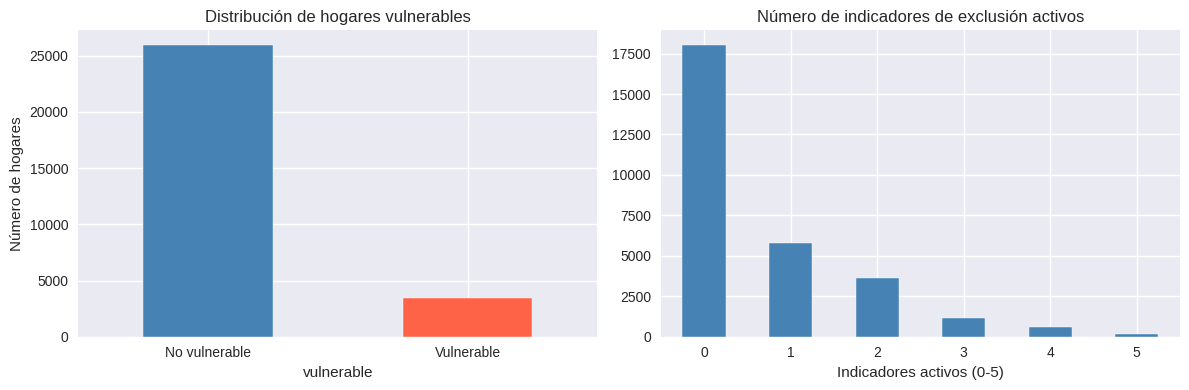

In [ ]:
# ============================================================
# CONSTRUCCIÓN DE LA VARIABLE OBJETIVO
# Todo sobre df_final
# ============================================================

# -- Indicadores binarios de exclusión financiera --
# Contamos como "excluido" cualquier retraso: código 1 (una vez) O código 2 (dos veces o más)

df_final['exc_retraso_vivienda']   = (df_final['HS011'].isin([1, 2])).astype(int)
df_final['exc_retraso_facturas']   = (df_final['HS021'].isin([1, 2])).astype(int)
df_final['exc_retraso_prestamos']  = (df_final['HS031'].isin([1, 2])).astype(int)
df_final['exc_gastos_imprevistos'] = (df_final['HS060'] == 2).astype(int)  # 2=no puede (sin cambios)
df_final['exc_fin_de_mes'] = (df_final['HS120'].isin([1, 2])).astype(int)

# Suma total de indicadores de exclusión financiera
df_final['suma_exclusion'] = (
    df_final['exc_retraso_vivienda'] +
    df_final['exc_retraso_facturas'] +
    df_final['exc_retraso_prestamos'] +
    df_final['exc_gastos_imprevistos'] +
    df_final['exc_fin_de_mes']
)

# -- Variable objetivo combinada --
# Doblemente vulnerable = en riesgo de pobreza Y al menos 1 indicador de exclusión financiera activo
df_final['vulnerable'] = (
    (df_final['vhPobreza'] == 1) &
    (df_final['suma_exclusion'] >= 1)
).astype(int)
# Distribución
print("DISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
print("="*55)
print(df_final['vulnerable'].value_counts())
print(f"\nHogares NO vulnerables: {(df_final['vulnerable']==0).sum()} ({(df_final['vulnerable']==0).mean()*100:.1f}%)")
print(f"Hogares vulnerables:    {(df_final['vulnerable']==1).sum()} ({(df_final['vulnerable']==1).mean()*100:.1f}%)")

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_final['vulnerable'].value_counts().plot(
    kind='bar', ax=axes[0], color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Distribución de hogares vulnerables')
axes[0].set_xticklabels(['No vulnerable', 'Vulnerable'], rotation=0)
axes[0].set_ylabel('Número de hogares')

df_final['suma_exclusion'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Número de indicadores de exclusión activos')
axes[1].set_xlabel('Indicadores activos (0-5)')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/variable_objetivo.png',
            dpi=150, bbox_inches='tight')
plt.show()

Metodológicamente: un hogar en riesgo de pobreza que además tiene al menos un indicador de exclusión financiera (retrasos en pagos, incapacidad de afrontar imprevistos, dificultad para llegar a fin de mes) es una definición sólida, coherente con la literatura sobre vulnerabilidad socioeconómica y perfectamente justificable ante el tutor.

Técnicamente: 11,6% de casos positivos es un desbalanceo manejable. No es perfecto pero permite trabajar con ajuste de pesos en los modelos sin necesidad de recurrir a SMOTE, lo que simplifica el pipeline.

5. EDA

In [ ]:
# ============================================================
# 5.1. ANÁLISIS EXPLORATORIO DE DATOS (EDA)
# ============================================================

print("5.1 ESTADÍSTICAS DESCRIPTIVAS")
print("="*55)

# Variables numéricas continuas
print("\nVARIABLES CONTINUAS:")
vars_continuas = ['vhRentaa', 'HH030', 'HB120']
print(df_final[vars_continuas].describe().round(2))

# Variables categóricas — frecuencias
print("\nVARIABLES CATEGÓRICAS CLAVE:")
vars_cat = ['vhPobreza', 'vhMATDEP', 'vulnerable',
            'HS120', 'HS060', 'HH021', 'DB100']
for var in vars_cat:
    print(f"\n{var}:")
    print(df_final[var].value_counts(normalize=True).mul(100).round(1).to_string())

5.1 ESTADÍSTICAS DESCRIPTIVAS

VARIABLES CONTINUAS:
        vhRentaa     HH030     HB120
count   29369.00  29369.00  29369.00
mean    39896.35      4.88      2.43
std     27486.61      1.52      1.23
min    -28024.30      1.00      1.00
25%     21033.99      4.00      1.00
50%     34733.50      5.00      2.00
75%     51693.90      6.00      3.00
max    522875.20     10.00     13.00

VARIABLES CATEGÓRICAS CLAVE:

vhPobreza:
vhPobreza
0    83.0
1    17.0

vhMATDEP:
vhMATDEP
0    93.4
1     6.6

vulnerable:
vulnerable
0    88.4
1    11.6

HS120:
HS120
4.0    30.8
3.0    23.5
5.0    22.5
2.0    11.3
1.0     7.7
6.0     4.1

HS060:
HS060
1.0    67.0
2.0    33.0

HH021:
HH021
1    51.9
2    26.1
3    12.7
5     6.2
4     3.1

DB100:
DB100
1    52.7
2    31.8
3    15.5


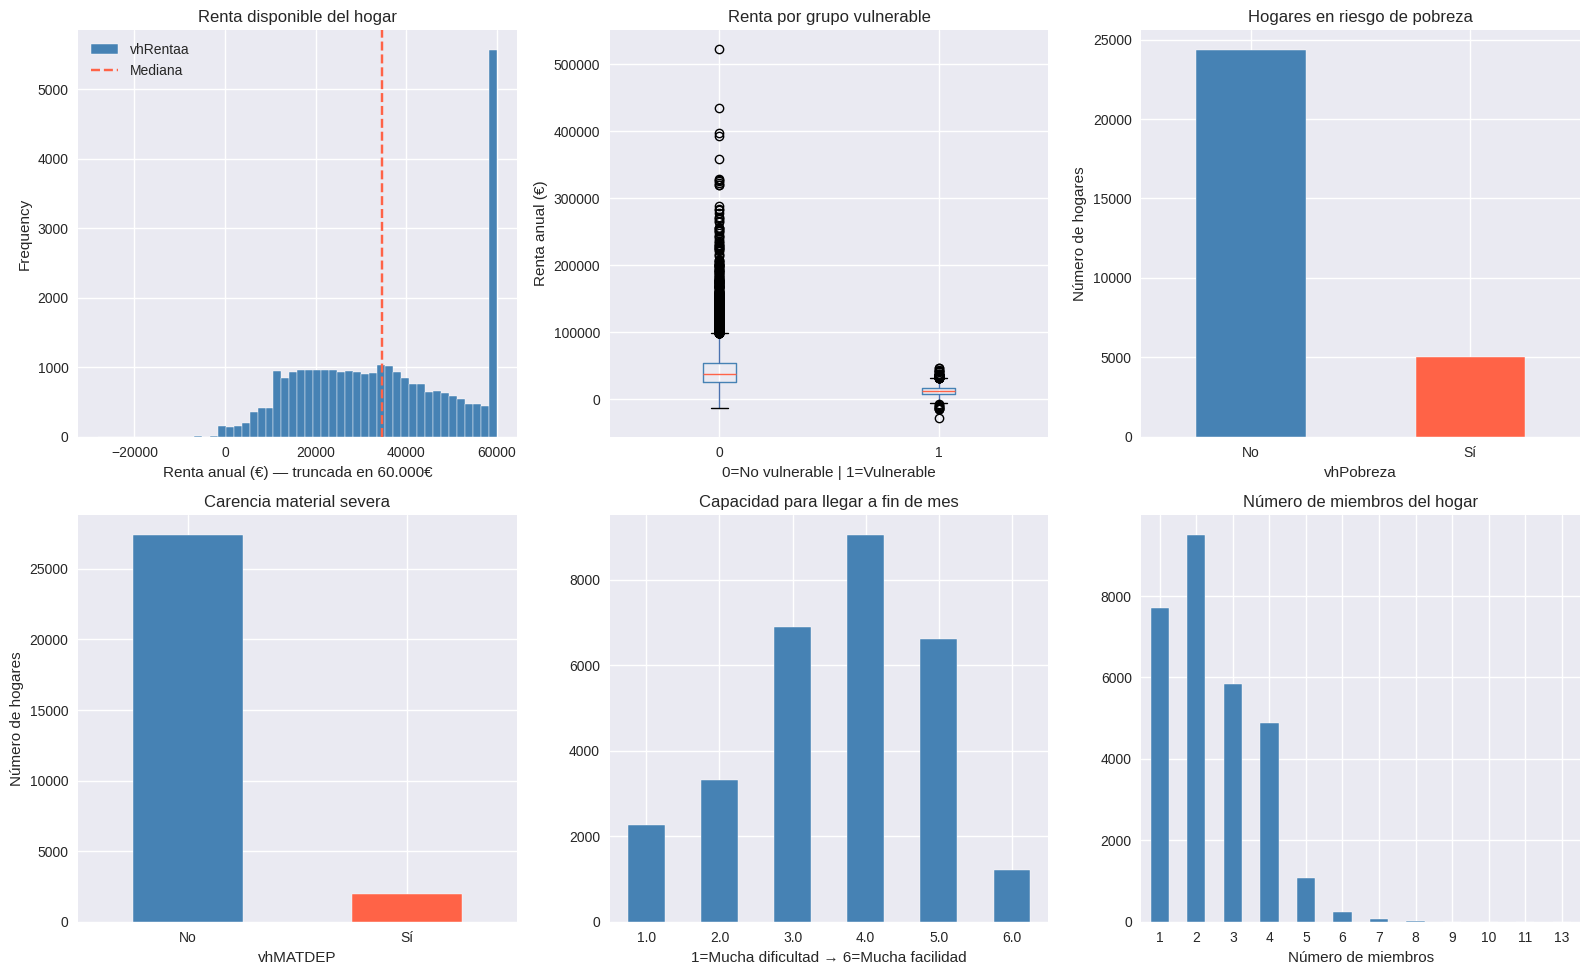

In [ ]:
# ============================================================
# 5.2.1 DISTRIBUCIÓN DE VARIABLES CLAVE — DIMENSIÓN POBREZA
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribución de variables de pobreza',
             fontsize=14, fontweight='bold')

# Renta del hogar
df_final['vhRentaa'].clip(upper=60000).plot(
    kind='hist', bins=50, ax=axes[0,0],
    color='steelblue', edgecolor='white')
axes[0,0].set_title('Renta disponible del hogar')
axes[0,0].set_xlabel('Renta anual (€) — truncada en 60.000€')
axes[0,0].axvline(df_final['vhRentaa'].median(),
                   color='tomato', linestyle='--', label='Mediana')
axes[0,0].legend()

# Renta por grupo vulnerable
df_final.boxplot(column='vhRentaa', by='vulnerable',
                  ax=axes[0,1],
                  boxprops=dict(color='steelblue'),
                  medianprops=dict(color='tomato'))
plt.suptitle('')
axes[0,1].set_title('Renta por grupo vulnerable')
axes[0,1].set_xlabel('0=No vulnerable | 1=Vulnerable')
axes[0,1].set_ylabel('Renta anual (€)')

# Riesgo de pobreza
df_final['vhPobreza'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0,2],
    color=['steelblue', 'tomato'], edgecolor='white')
axes[0,2].set_title('Hogares en riesgo de pobreza')
axes[0,2].set_xticklabels(['No', 'Sí'], rotation=0)
axes[0,2].set_ylabel('Número de hogares')

# Carencia material severa
df_final['vhMATDEP'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,0],
    color=['steelblue', 'tomato'], edgecolor='white')
axes[1,0].set_title('Carencia material severa')
axes[1,0].set_xticklabels(['No', 'Sí'], rotation=0)
axes[1,0].set_ylabel('Número de hogares')

# Capacidad llegar a fin de mes
df_final['HS120'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,1],
    color='steelblue', edgecolor='white')
axes[1,1].set_title('Capacidad para llegar a fin de mes')
axes[1,1].set_xlabel('1=Mucha dificultad → 6=Mucha facilidad')
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=0)

# Número de miembros del hogar
df_final['HB120'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,2],
    color='steelblue', edgecolor='white')
axes[1,2].set_title('Número de miembros del hogar')
axes[1,2].set_xlabel('Número de miembros')
axes[1,2].set_xticklabels(axes[1,2].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/EDA_pobreza.png',
            dpi=150, bbox_inches='tight')
plt.show()

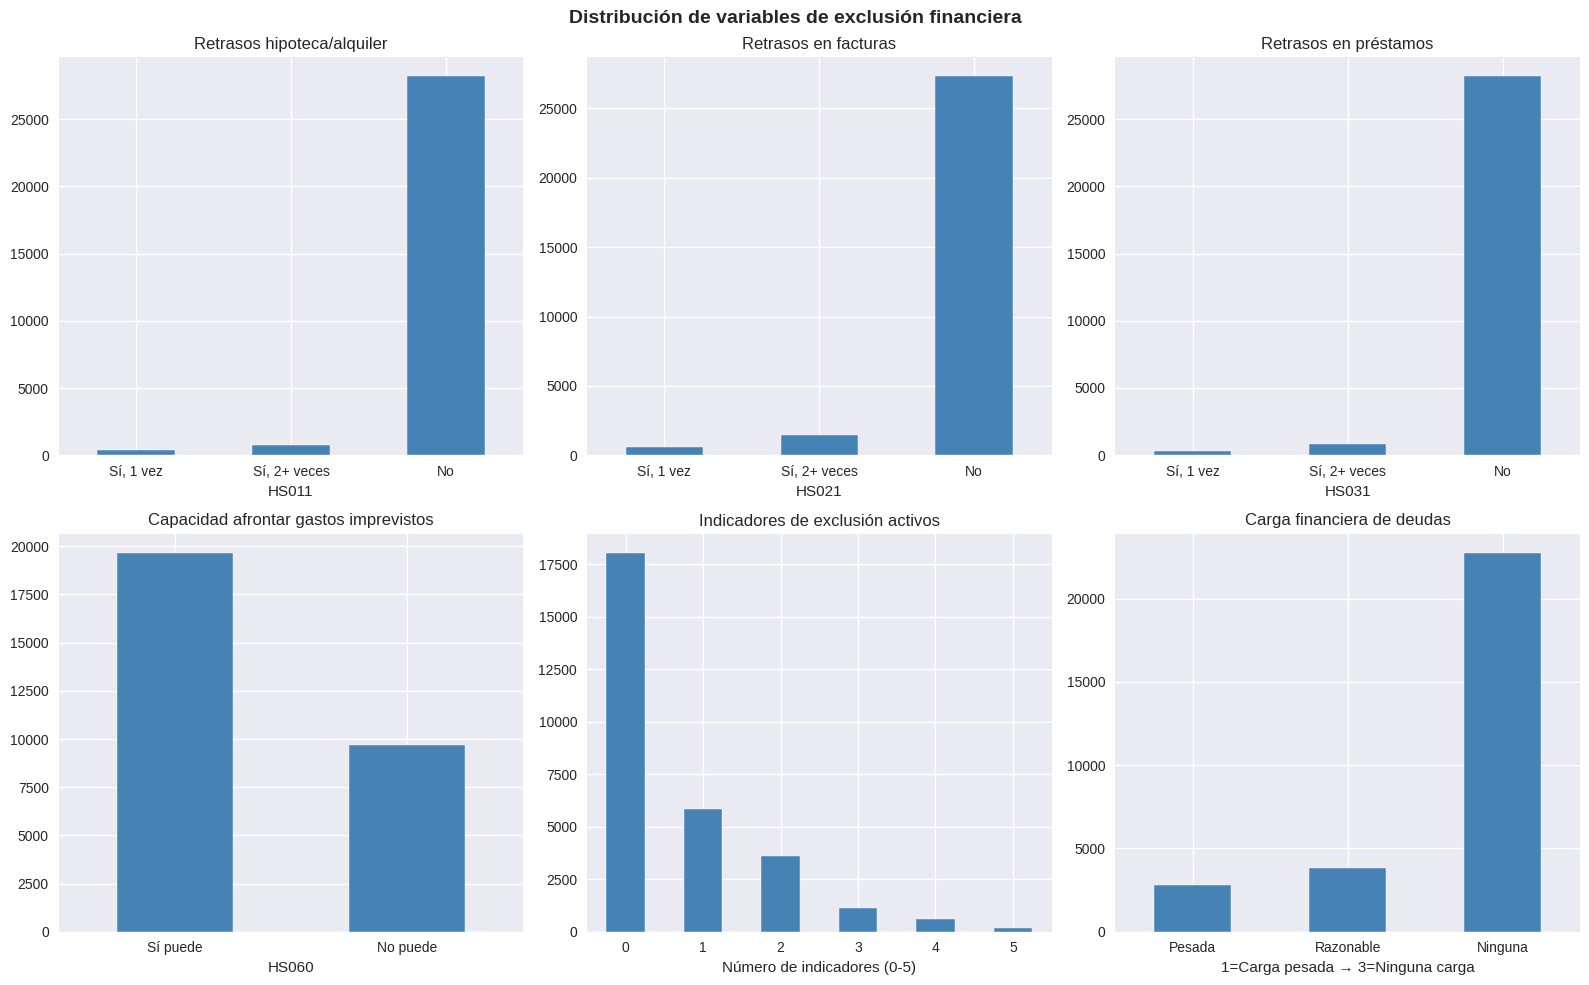

In [ ]:
# ============================================================
# 5.2.2 DISTRIBUCIÓN DE VARIABLES CLAVE — DIMENSIÓN EXCLUSIÓN
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribución de variables de exclusión financiera',
             fontsize=14, fontweight='bold')

etiquetas_retraso = ['Sí, 1 vez', 'Sí, 2+ veces', 'No']  # códigos 1, 2, 3

# Retrasos hipoteca/alquiler
df_final['HS011'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0,0], color='steelblue', edgecolor='white')
axes[0,0].set_title('Retrasos hipoteca/alquiler')
axes[0,0].set_xticklabels(etiquetas_retraso, rotation=0)

# Retrasos facturas
df_final['HS021'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0,1], color='steelblue', edgecolor='white')
axes[0,1].set_title('Retrasos en facturas')
axes[0,1].set_xticklabels(etiquetas_retraso, rotation=0)

# Retrasos préstamos
df_final['HS031'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0,2], color='steelblue', edgecolor='white')
axes[0,2].set_title('Retrasos en préstamos')
axes[0,2].set_xticklabels(etiquetas_retraso, rotation=0)

# Capacidad afrontar gastos imprevistos (esta sí es binaria: 1=Sí, 2=No)
df_final['HS060'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,0], color='steelblue', edgecolor='white')
axes[1,0].set_title('Capacidad afrontar gastos imprevistos')
axes[1,0].set_xticklabels(['Sí puede', 'No puede'], rotation=0)

# Suma de indicadores de exclusión
df_final['suma_exclusion'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,1], color='steelblue', edgecolor='white')
axes[1,1].set_title('Indicadores de exclusión activos')
axes[1,1].set_xlabel('Número de indicadores (0-5)')
axes[1,1].set_xticklabels(axes[1,1].get_xticklabels(), rotation=0)

# Carga financiera deudas (1=carga pesada, 2=razonable, 3=ninguna)
df_final['HS150'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1,2], color='steelblue', edgecolor='white')
axes[1,2].set_title('Carga financiera de deudas')
axes[1,2].set_xlabel('1=Carga pesada → 3=Ninguna carga')
axes[1,2].set_xticklabels(['Pesada', 'Razonable', 'Ninguna'], rotation=0)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/EDA_exclusion.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print(df_final['suma_exclusion'].value_counts().sort_index())
print(f"\nSuma total: {df_final['suma_exclusion'].value_counts().sum()}")

suma_exclusion
0    18037
1     5824
2     3601
3     1130
4      590
5      187
Name: count, dtype: int64

Suma total: 29369


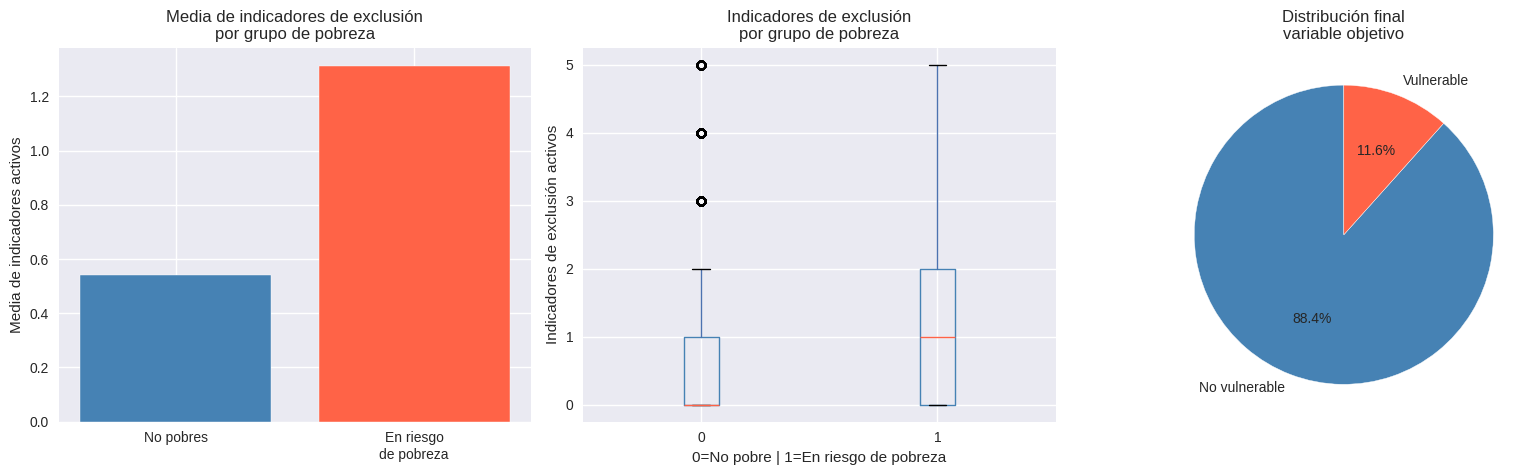


TABLA RESUMEN — POBREZA VS EXCLUSIÓN FINANCIERA
Con exclusión financiera  False   True    All
En riesgo pobreza                            
0                         16451   7917  24368
1                          1586   3415   5001
All                       18037  11332  29369


In [ ]:
# ============================================================
# 5.2.3 ANÁLISIS CONJUNTO — POBREZA Y EXCLUSIÓN FINANCIERA
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Relación entre pobreza y exclusión financiera',
             fontsize=14, fontweight='bold')

# % de exclusión financiera entre pobres vs no pobres
excluidos_pobres = df_final[df_final['vhPobreza']==1]['suma_exclusion'].mean()
excluidos_no_pobres = df_final[df_final['vhPobreza']==0]['suma_exclusion'].mean()

axes[0].bar(['No pobres', 'En riesgo\nde pobreza'],
            [excluidos_no_pobres, excluidos_pobres],
            color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Media de indicadores de exclusión\npor grupo de pobreza')
axes[0].set_ylabel('Media de indicadores activos')

# Distribución suma_exclusion por grupo vulnerable
df_final.boxplot(column='suma_exclusion', by='vhPobreza',
                  ax=axes[1],
                  boxprops=dict(color='steelblue'),
                  medianprops=dict(color='tomato'))
plt.suptitle('')
axes[1].set_title('Indicadores de exclusión\npor grupo de pobreza')
axes[1].set_xlabel('0=No pobre | 1=En riesgo de pobreza')
axes[1].set_ylabel('Indicadores de exclusión activos')

# Variable objetivo final
sizes = df_final['vulnerable'].value_counts()
axes[2].pie(sizes, labels=['No vulnerable', 'Vulnerable'],
            colors=['steelblue', 'tomato'],
            autopct='%1.1f%%', startangle=90,
            wedgeprops=dict(edgecolor='white'))
axes[2].set_title('Distribución final\nvariable objetivo')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/EDA_conjunto.png',
            dpi=150, bbox_inches='tight')
plt.show()

# Tabla resumen
print("\nTABLA RESUMEN — POBREZA VS EXCLUSIÓN FINANCIERA")
print("="*55)
tabla = pd.crosstab(
    df_final['vhPobreza'],
    df_final['suma_exclusion'] >= 1,
    rownames=['En riesgo pobreza'],
    colnames=['Con exclusión financiera'],
    margins=True
)
print(tabla)

In [ ]:
print(df_final.groupby('vulnerable')['vhRentaa'].agg(['median', 'mean']).round(2))

              median      mean
vulnerable                    
0           37680.25  43401.23
1           11910.30  13259.26


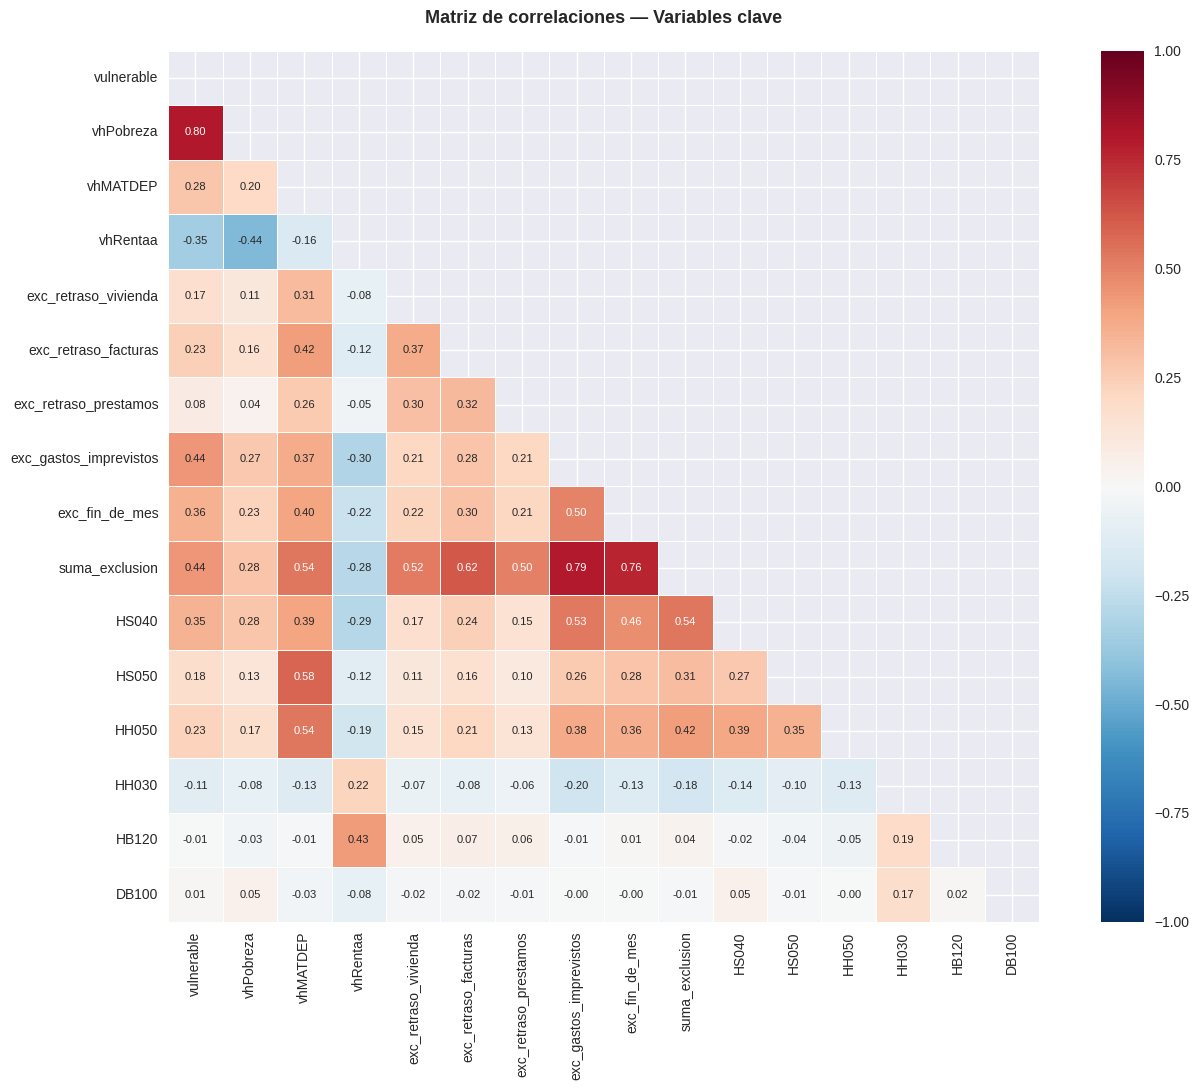

vhPobreza, vhMATDEP y las variables exc_*/suma_exclusion
van a salir con una correlación altísima con 'vulnerable' --> pero es porque
son las piezas con las que se construyo esa variable (ver apartado 4), no
porque se haya descubierto que predicen muy bien. Las correlaciones que
de verdad interesan de cara al modelo son las del resto de variables (vhRentaa, HS040,
HS050, HH050, HH030, HB120, DB100), que sí son candidatas reales a predictoras.

CORRELACIONES CON LA VARIABLE OBJETIVO (vulnerable)
vhPobreza                 0.801
suma_exclusion            0.440
exc_gastos_imprevistos    0.438
exc_fin_de_mes            0.355
vhRentaa                 -0.352
HS040                     0.348
vhMATDEP                  0.278
exc_retraso_facturas      0.235
HH050                     0.230
HS050                     0.178
exc_retraso_vivienda      0.165
HH030                    -0.109
exc_retraso_prestamos     0.084
DB100                     0.014
HB120                    -0.008


In [ ]:
# ============================================================
# 5.3 MATRIZ DE CORRELACIONES
# ============================================================

vars_correlacion = [
    'vulnerable', 'vhPobreza', 'vhMATDEP', 'vhRentaa',
    'exc_retraso_vivienda', 'exc_retraso_facturas',
    'exc_retraso_prestamos', 'exc_gastos_imprevistos',
    'exc_fin_de_mes', 'suma_exclusion',
    'HS040', 'HS050', 'HH050', 'HH030', 'HB120', 'DB100'
]

plt.figure(figsize=(14, 11))
corr = df_final[vars_correlacion].corr()
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # solo triángulo inferior

sns.heatmap(corr,
            mask=mask,
            annot=True, fmt='.2f',
            cmap='RdBu_r', center=0,
            square=True, linewidths=0.5,
            annot_kws={'size': 8},
            vmin=-1, vmax=1)
plt.title('Matriz de correlaciones — Variables clave',
          fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/correlaciones.png',
            dpi=150, bbox_inches='tight')
plt.show()

print("vhPobreza, vhMATDEP y las variables exc_*/suma_exclusion")
print("van a salir con una correlación altísima con 'vulnerable' --> pero es porque")
print("son las piezas con las que se construyo esa variable (ver apartado 4), no")
print("porque se haya descubierto que predicen muy bien. Las correlaciones que")
print("de verdad interesan de cara al modelo son las del resto de variables (vhRentaa, HS040,")
print("HS050, HH050, HH030, HB120, DB100), que sí son candidatas reales a predictoras.")

# Top correlaciones con la variable objetivo
print("\nCORRELACIONES CON LA VARIABLE OBJETIVO (vulnerable)")
print("="*55)
corr_target = corr['vulnerable'].drop('vulnerable').sort_values(
    key=abs, ascending=False)
print(corr_target.round(3).to_string())

VULNERABILIDAD POR COMUNIDAD AUTÓNOMA
                    n_hogares  n_vulnerables  pct_vulnerables  renta_media  excluidos_media
CCAA_nombre                                                                                
Melilla                   187             47             25.1      41892.0            0.979
Ceuta                     209             50             23.9      43923.0            1.019
Andalucía                3206            609             19.0      34048.0            0.915
Extremadura              1079            196             18.2      29895.0            0.754
Murcia                   1173            212             18.1      34597.0            0.890
Canarias                 1059            187             17.7      35756.0            0.906
Castilla-La Mancha       1200            193             16.1      34954.0            0.753
C. Valenciana            2308            347             15.0      35904.0            0.699
Galicia                  1630            1

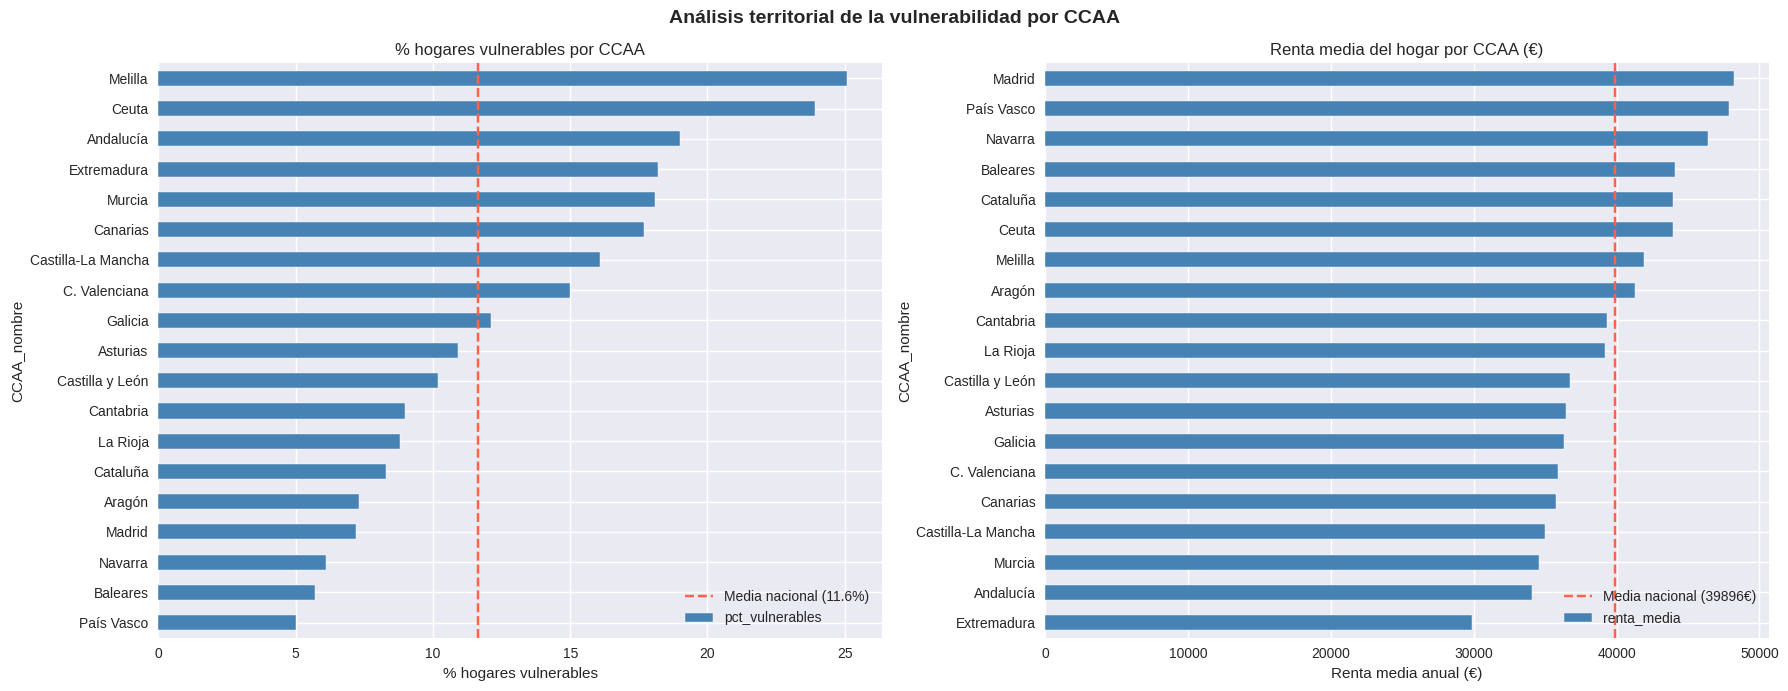

In [ ]:
# ============================================================
# 5.4.1 ANÁLISIS TERRITORIAL POR COMUNIDAD AUTÓNOMA
# ============================================================

# Diccionario de códigos CCAA del INE
ccaa_nombres = {
    'ES11': 'Galicia', 'ES12': 'Asturias', 'ES13': 'Cantabria',
    'ES21': 'País Vasco', 'ES22': 'Navarra', 'ES23': 'La Rioja',
    'ES24': 'Aragón', 'ES30': 'Madrid', 'ES41': 'Castilla y León',
    'ES42': 'Castilla-La Mancha', 'ES43': 'Extremadura',
    'ES51': 'Cataluña', 'ES52': 'C. Valenciana', 'ES53': 'Baleares',
    'ES61': 'Andalucía', 'ES62': 'Murcia', 'ES63': 'Ceuta',
    'ES64': 'Melilla', 'ES70': 'Canarias'
}

df_final['CCAA_nombre'] = df_final['DB040'].map(ccaa_nombres)

# % vulnerables por CCAA
vulnerables_ccaa = df_final.groupby('CCAA_nombre').agg(
    n_hogares=('vulnerable', 'count'),
    n_vulnerables=('vulnerable', 'sum'),
    pct_vulnerables=('vulnerable', 'mean'),
    renta_media=('vhRentaa', 'mean'),
    excluidos_media=('suma_exclusion', 'mean')
).round(3)

vulnerables_ccaa['pct_vulnerables'] = (
    vulnerables_ccaa['pct_vulnerables'] * 100).round(1)
vulnerables_ccaa['renta_media'] = vulnerables_ccaa['renta_media'].round(0)

vulnerables_ccaa = vulnerables_ccaa.sort_values(
    'pct_vulnerables', ascending=False)

print("VULNERABILIDAD POR COMUNIDAD AUTÓNOMA")
print("="*55)
print(vulnerables_ccaa.to_string())

# Visualización
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Análisis territorial de la vulnerabilidad por CCAA',
             fontsize=14, fontweight='bold')

# % vulnerables por CCAA
vulnerables_ccaa['pct_vulnerables'].sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('% hogares vulnerables por CCAA')
axes[0].set_xlabel('% hogares vulnerables')
axes[0].axvline(df_final['vulnerable'].mean()*100,
                color='tomato', linestyle='--',
                label=f'Media nacional ({df_final["vulnerable"].mean()*100:.1f}%)')
axes[0].legend()

# Renta media por CCAA
vulnerables_ccaa['renta_media'].sort_values().plot(
    kind='barh', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Renta media del hogar por CCAA (€)')
axes[1].set_xlabel('Renta media anual (€)')
axes[1].axvline(df_final['vhRentaa'].mean(),
                color='tomato', linestyle='--',
                label=f'Media nacional ({df_final["vhRentaa"].mean():.0f}€)')
axes[1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/EDA_territorial.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
print(f"Total de hogares en el dataset: {len(df_final)}")
print(f"Total de hogares tras agrupar por CCAA: {vulnerables_ccaa['n_hogares'].sum()}")
print(f"Hogares con CCAA no mapeada (NaN): {df_final['CCAA_nombre'].isna().sum()}")

if df_final['CCAA_nombre'].isna().sum() > 0:
    print("\n⚠️ Códigos DB040 sin mapear:")
    print(df_final[df_final['CCAA_nombre'].isna()]['DB040'].unique())

Total de hogares en el dataset: 29369
Total de hogares tras agrupar por CCAA: 29369
Hogares con CCAA no mapeada (NaN): 0


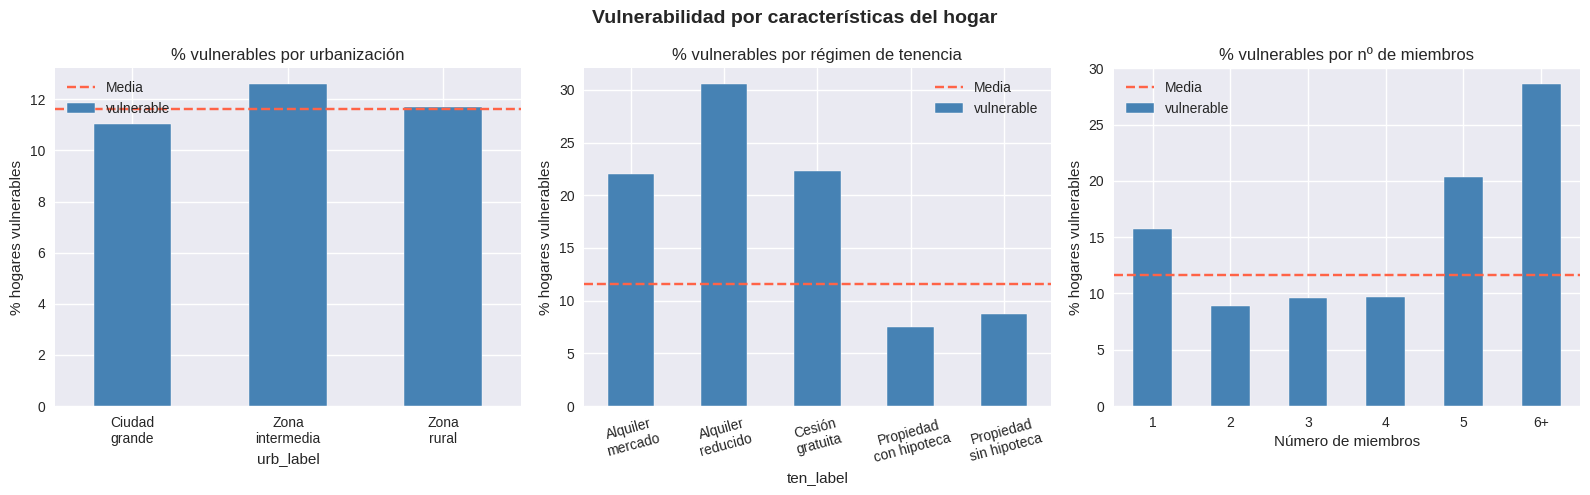

In [ ]:
# ============================================================
# 5.4.2 ANÁLISIS POR URBANIZACIÓN Y TIPO DE HOGAR
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Vulnerabilidad por características del hogar',
             fontsize=14, fontweight='bold')

# Por grado de urbanización
urb_labels = {1: 'Ciudad\ngrande', 2: 'Zona\nintermedia', 3: 'Zona\nrural'}
df_final['urb_label'] = df_final['DB100'].map(urb_labels)
df_final.groupby('urb_label')['vulnerable'].mean().mul(100).plot(
    kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('% vulnerables por urbanización')
axes[0].set_ylabel('% hogares vulnerables')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].axhline(df_final['vulnerable'].mean()*100,
                color='tomato', linestyle='--', label='Media')
axes[0].legend()

# Por régimen de tenencia
ten_labels = {1: 'Propiedad\nsin hipoteca', 2: 'Propiedad\ncon hipoteca',
              3: 'Alquiler\nmercado', 4: 'Alquiler\nreducido',
              5: 'Cesión\ngratuita'}
df_final['ten_label'] = df_final['HH021'].map(ten_labels)
df_final.groupby('ten_label')['vulnerable'].mean().mul(100).plot(
    kind='bar', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('% vulnerables por régimen de tenencia')
axes[1].set_ylabel('% hogares vulnerables')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=15)
axes[1].axhline(df_final['vulnerable'].mean()*100,
                color='tomato', linestyle='--', label='Media')
axes[1].legend()

# Por número de miembros(se agrupa 6 o más miembros en una sola barra, porque
# hay muy pocos hogares tan grandes y si no, saldrían barras poco fiables)
df_final['HB120_grupo'] = df_final['HB120'].apply(lambda x: '6+' if x >= 6 else str(int(x)))
orden_categorias = ['1', '2', '3', '4', '5', '6+']

df_final.groupby('HB120_grupo')['vulnerable'].mean().reindex(orden_categorias).mul(100).plot(
    kind='bar', ax=axes[2], color='steelblue', edgecolor='white')
axes[2].set_title('% vulnerables por nº de miembros')
axes[2].set_ylabel('% hogares vulnerables')
axes[2].set_xlabel('Número de miembros')
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].axhline(df_final['vulnerable'].mean()*100,
                color='tomato', linestyle='--', label='Media')
axes[2].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/outputs/graficos/EDA_hogar.png',
            dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# Desglose de vulnerabilidad dentro de los hogares unipersonales (HX060 = 1 a 6)
unipersonales = df_final[df_final['HX060'].isin([1,2,3,4,5,6])]
etiquetas_unip = {
    1: 'Hombre <30', 2: 'Hombre 30-64', 3: 'Hombre 65+',
    4: 'Mujer <30', 5: 'Mujer 30-64', 6: 'Mujer 65+'
}
print(unipersonales.groupby('HX060')['vulnerable'].agg(['mean', 'count']).rename(index=etiquetas_unip))

                  mean  count
HX060                        
Hombre <30    0.175182    137
Hombre 30-64  0.145806   2325
Hombre 65+    0.103233    959
Mujer <30     0.261682    107
Mujer 30-64   0.184310   1861
Mujer 65+     0.164590   2327


In [ ]:
# ============================================================
# GUARDAR DATASET TRAS EDA
# ============================================================
ruta_output = '/content/drive/MyDrive/TFM/datos_2025/processed/'
os.makedirs(ruta_output, exist_ok=True)

df_final.to_csv(f'{ruta_output}df_ecv_eda.csv', index=False)

print("✅ Dataset guardado tras EDA")
print(f"   Dimensiones: {df_final.shape}")
print(f"   Columnas: {list(df_final.columns)}")
print(f"   Vulnerables: {df_final['vulnerable'].sum()} ({df_final['vulnerable'].mean()*100:.1f}%)")

✅ Dataset guardado tras EDA
   Dimensiones: (29369, 33)
   Columnas: ['DB030', 'DB040', 'DB100', 'vhPobreza', 'vhMATDEP', 'vhRentaa', 'HS011', 'HS021', 'HS031', 'HS060', 'HS120', 'HS150', 'HS040', 'HS050', 'HH050', 'HS090', 'HS110', 'HH010', 'HH021', 'HH030', 'HB120', 'HX060', 'exc_retraso_vivienda', 'exc_retraso_facturas', 'exc_retraso_prestamos', 'exc_gastos_imprevistos', 'exc_fin_de_mes', 'suma_exclusion', 'vulnerable', 'CCAA_nombre', 'urb_label', 'ten_label', 'HB120_grupo']
   Vulnerables: 3415 (11.6%)


6. División del conjunto de datos** **texto en negrita

Introducción

Antes de realizar cualquier transformación sobre los datos, es necesario dividir el conjunto de datos en dos subconjuntos independientes: entrenamiento y prueba. Esta separación permite evaluar posteriormente la capacidad de generalización de los modelos de Machine Learning utilizando información no vista durante el entrenamiento.

En este trabajo se emplea una división del 80 % para entrenamiento y 20 % para prueba, ya que constituye una proporción ampliamente utilizada en la literatura y proporciona un equilibrio adecuado entre la cantidad de datos disponibles para entrenar los modelos y la capacidad de realizar una evaluación fiable.

Asimismo, se emplea una división estratificada respecto a la variable objetivo. Esta estrategia garantiza que la proporción de hogares vulnerables y no vulnerables permanezca aproximadamente constante en ambos subconjuntos, aspecto especialmente importante cuando existen clases desbalanceadas.

Finalmente, se fija una semilla aleatoria (random_state = 42) con el objetivo de asegurar la reproducibilidad del estudio.

In [ ]:
# ============================================================
# 6.1 DEFINICIÓN DE X, y Y DIVISIÓN TRAIN/TEST
# ============================================================
from sklearn.model_selection import train_test_split

# Variables excluidas por fuga de información (determinan el target)
vars_fuga = ['vhPobreza', 'HS011', 'HS021', 'HS031', 'HS060', 'HS120',
             'exc_retraso_vivienda', 'exc_retraso_facturas',
             'exc_retraso_prestamos', 'exc_gastos_imprevistos',
             'exc_fin_de_mes', 'suma_exclusion',
             'vhMATDEP']  # caso límite, excluida del modelo principal

# Identificadores / auxiliares que tampoco son predictores
vars_no_predictoras = ['DB030', 'CCAA_nombre', 'urb_label', 'ten_label', 'HB120_grupo']

y = df_final['vulnerable']
X = df_final.drop(columns=['vulnerable'] + vars_fuga + vars_no_predictoras,
                   errors='ignore')

# Elegimos solo una variable de "número de miembros" (evitar redundancia)
X = X.drop(columns=['HX040'], errors='ignore')  # nos quedamos con HB120

print(f"Predictoras finales ({X.shape[1]}): {list(X.columns)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"\nTrain: {X_train.shape} | % vulnerables: {y_train.mean()*100:.1f}%")
print(f"Test:  {X_test.shape} | % vulnerables: {y_test.mean()*100:.1f}%")

Predictoras finales (14): ['DB040', 'DB100', 'vhRentaa', 'HS150', 'HS040', 'HS050', 'HH050', 'HS090', 'HS110', 'HH010', 'HH021', 'HH030', 'HB120', 'HX060']

Train: (23495, 14) | % vulnerables: 11.6%
Test:  (5874, 14) | % vulnerables: 11.6%


In [ ]:
# ============================================================
# 6.2–6.3 PIPELINE DE PREPROCESAMIENTO
# ============================================================
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Nominales sin orden natural → OneHot
# HS090 y HS110 se tratan aquí, no como ordinales: aunque están codificadas
# con números (1, 2, 3), el código 3 ("no por otro motivo") no representa un
# grado mayor que el código 2 ("no por no poder permitírselo") en ninguna
# escala real — son categorías distintas, no una progresión.
vars_nominales = ['DB040', 'HH010', 'HH021', 'HX060', 'HS090', 'HS110']

# El resto de ordinales sí tienen una progresión real de por medio (más o
# menos privación, más o menos urbanización). SVM y la regresión se benefician de tenerlas
# estandarizadas; lo revisamos con más detalle en el apartado 7.3.
vars_ordinales = ['DB100', 'HS040', 'HS050', 'HH050', 'HS150']

# Continuas → StandardScaler
vars_continuas = ['vhRentaa', 'HH030', 'HB120']

preprocesador = ColumnTransformer(transformers=[
    ('nominal', OneHotEncoder(handle_unknown='ignore', drop='first'), vars_nominales),
    ('ordinal', StandardScaler(), vars_ordinales),   # estandarizamos también las ordinales
    ('continua', StandardScaler(), vars_continuas),
], remainder='drop')

# Fit SOLO con train, transform en ambos (para evitar fuga de información)
X_train_prep = preprocesador.fit_transform(X_train)
X_test_prep = preprocesador.transform(X_test)

print(f"Dimensiones tras preprocesado — train: {X_train_prep.shape}, test: {X_test_prep.shape}")

# Nombres de columnas resultantes
nombres_ohe = preprocesador.named_transformers_['nominal'].get_feature_names_out(vars_nominales)
nombres_finales = list(nombres_ohe) + vars_ordinales + vars_continuas

Dimensiones tras preprocesado — train: (23495, 50), test: (5874, 50)


In [ ]:
# ============================================================
# 6.4 GESTIÓN DEL DESBALANCEO — DECISIÓN: PESOS (no SMOTE)
# ============================================================
# Justificación: 11.6% de positivos es un
# desbalanceo moderado. Usamos class_weight='balanced' en cada modelo
# en vez de SMOTE, para no generar hogares sintéticos que compliquen la
# interpretabilidad ante el tribunal.

ruta_output = '/content/drive/MyDrive/TFM/datos_2025/processed/'
os.makedirs(ruta_output, exist_ok=True)

with open(f'{ruta_output}preprocesador.pkl', 'wb') as f:
    pickle.dump(preprocesador, f)

print("✅ Pipeline de preprocesado guardado")
print("✅ Decisión de desbalanceo: class_weight='balanced' en LR, RF y SVM")

✅ Pipeline de preprocesado guardado
✅ Decisión de desbalanceo: class_weight='balanced' en LR, RF y SVM


7. Modelización

In [ ]:
# ============================================================
# 7.1 REGRESIÓN LOGÍSTICA
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'f1', 'recall', 'precision']

# Búsqueda del mejor C
param_grid_lr = {'C': [0.01, 0.1, 1, 10, 100, 500]}
grid_lr = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    param_grid_lr, cv=cv, scoring='f1', n_jobs=-1
)
grid_lr.fit(X_train_prep, y_train)
print(f"Mejor C encontrado: {grid_lr.best_params_['C']}")
print(f"F1 en validación cruzada durante la búsqueda: {grid_lr.best_score_:.3f}")

# Modelo final con el mejor C, evaluado con las 4 métricas
log_reg = grid_lr.best_estimator_

cv_resultados_lr = cross_validate(
    log_reg, X_train_prep, y_train, cv=cv, scoring=scoring
)

print("\nREGRESIÓN LOGÍSTICA — VALIDACIÓN CRUZADA (5-fold)")
print("="*55)
for metrica in scoring:
    valores = cv_resultados_lr[f'test_{metrica}']
    print(f"{metrica:12s}: {valores.mean():.3f} (+/- {valores.std():.3f})")

# Entrenamiento final sobre todo el train para evaluar el test más adelante
log_reg.fit(X_train_prep, y_train)

Mejor C encontrado: 500
F1 en validación cruzada durante la búsqueda: 0.737

REGRESIÓN LOGÍSTICA — VALIDACIÓN CRUZADA (5-fold)
roc_auc     : 0.975 (+/- 0.002)
f1          : 0.737 (+/- 0.009)
recall      : 0.965 (+/- 0.005)
precision   : 0.596 (+/- 0.012)


LogisticRegression(C=500, class_weight='balanced', max_iter=1000,
                   random_state=42)

In [ ]:
# ============================================================
# 7.2 RANDOM FOREST (con ajuste de hiperparámetros)
# ============================================================
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 5, 10]
}

grid_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid_rf, cv=cv, scoring='f1', n_jobs=-1
)
grid_rf.fit(X_train_prep, y_train)
print(f"Mejores hiperparámetros: {grid_rf.best_params_}")
print(f"F1 en validación cruzada durante la búsqueda: {grid_rf.best_score_:.3f}")

rf = grid_rf.best_estimator_

cv_resultados_rf = cross_validate(
    rf, X_train_prep, y_train, cv=cv, scoring=scoring
)

print("\nRANDOM FOREST — VALIDACIÓN CRUZADA (5-fold)")
print("="*55)
for metrica in scoring:
    valores = cv_resultados_rf[f'test_{metrica}']
    print(f"{metrica:12s}: {valores.mean():.3f} (+/- {valores.std():.3f})")

rf.fit(X_train_prep, y_train)

Mejores hiperparámetros: {'max_depth': 20, 'min_samples_leaf': 1}
F1 en validación cruzada durante la búsqueda: 0.795

RANDOM FOREST — VALIDACIÓN CRUZADA (5-fold)
roc_auc     : 0.981 (+/- 0.002)
f1          : 0.795 (+/- 0.011)
recall      : 0.803 (+/- 0.008)
precision   : 0.788 (+/- 0.019)


RandomForestClassifier(class_weight='balanced', max_depth=20, n_estimators=300,
                       n_jobs=-1, random_state=42)

In [ ]:
# ============================================================
# 7.3 SUPPORT VECTOR MACHINE (SVM) - CON AJUSTE DE HIPERPARÁMETROS (grid completo)
# ============================================================
from sklearn.svm import SVC

param_grid_svm = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}

svm_grid = GridSearchCV(
    SVC(class_weight='balanced', probability=True, random_state=42),
    param_grid_svm, cv=cv, scoring='f1', n_jobs=-1
)

svm_grid.fit(X_train_prep, y_train)
svm = svm_grid.best_estimator_

print(f"Mejores hiperparámetros SVM: {svm_grid.best_params_}")

cv_resultados_svm = cross_validate(
    svm, X_train_prep, y_train, cv=cv, scoring=scoring
)

print("\nSVM — VALIDACIÓN CRUZADA (5-fold)")
print("="*55)
for metrica in scoring:
    valores = cv_resultados_svm[f'test_{metrica}']
    print(f"{metrica:12s}: {valores.mean():.3f} (+/- {valores.std():.3f})")

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Mejores hiperparámetros SVM: {'C': 10, 'kernel': 'linear'}

SVM — VALIDACIÓN CRUZADA (5-fold)
roc_auc     : 0.974 (+/- 0.002)
f1          : 0.738 (+/- 0.011)
recall      : 0.987 (+/- 0.005)
precision   : 0.589 (+/- 0.013)


In [ ]:
# ============================================================
# 7.3 SVM — VERIFICACIÓN DE BORDE (solo kernel lineal, C más alto)
# ============================================================
param_grid_svm_ampliado = {'C': [10, 50, 100], 'kernel': ['linear']}

svm_grid2 = GridSearchCV(
    SVC(class_weight='balanced', probability=True, random_state=42),
    param_grid_svm_ampliado, cv=cv, scoring='f1', n_jobs=-1
)
svm_grid2.fit(X_train_prep, y_train)
svm = svm_grid2.best_estimator_

print(f"Mejor C (ampliado, solo lineal): {svm_grid2.best_params_['C']}")

cv_resultados_svm = cross_validate(
    svm, X_train_prep, y_train, cv=cv, scoring=scoring
)

print("\nSVM — VALIDACIÓN CRUZADA (5-fold)")
print("="*55)
for metrica in scoring:
    valores = cv_resultados_svm[f'test_{metrica}']
    print(f"{metrica:12s}: {valores.mean():.3f} (+/- {valores.std():.3f})")

Mejor C (ampliado, solo lineal): 100

SVM — VALIDACIÓN CRUZADA (5-fold)
roc_auc     : 0.974 (+/- 0.002)
f1          : 0.738 (+/- 0.011)
recall      : 0.987 (+/- 0.005)
precision   : 0.590 (+/- 0.013)


k=2: inercia=283036, silhouette=0.177
k=3: inercia=255294, silhouette=0.118
k=4: inercia=232780, silhouette=0.123
k=5: inercia=216753, silhouette=0.134
k=6: inercia=204026, silhouette=0.126
k=7: inercia=193362, silhouette=0.132
k=8: inercia=187189, silhouette=0.117


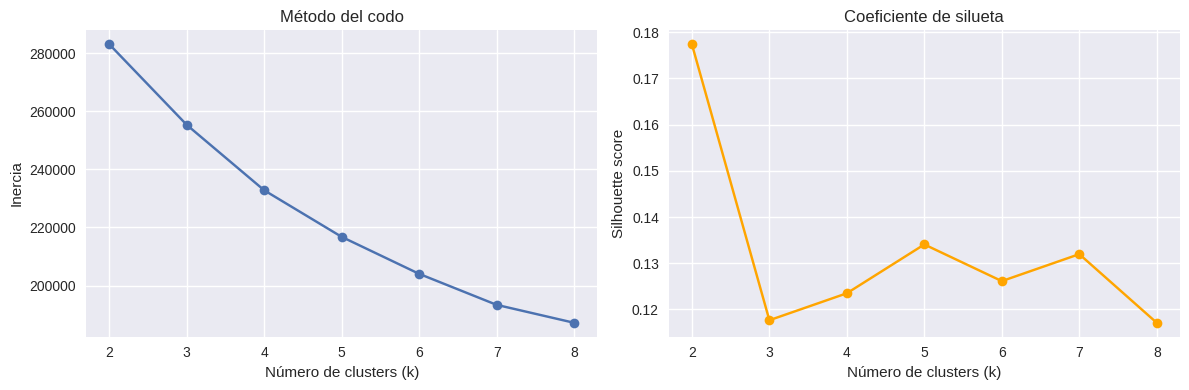

In [ ]:
# ============================================================
# 7.4 CLUSTERING NO SUPERVISADO — K-MEANS
# ============================================================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_completo_prep = preprocesador.transform(X)

inercias = []
siluetas = []
rango_k = range(2, 9)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=30)
    labels = km.fit_predict(X_completo_prep)
    sil = silhouette_score(X_completo_prep, labels, sample_size=5000, random_state=42)

    inercias.append(km.inertia_)
    siluetas.append(sil)

    print(f"k={k}: inercia={km.inertia_:.0f}, silhouette={sil:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(rango_k), inercias, marker='o')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo')

axes[1].plot(list(rango_k), siluetas, marker='o', color='orange')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Coeficiente de silueta')
plt.tight_layout()
plt.show()

En los gráficos anteriores se observa:

1. No hay un "codo" muy marcado. La gráfica desciende de forma suave y progresiva (283.036 → 187.189 entre k=2 y k=8) sin un punto donde caiga bruscamente y luego se aplane —> es una curva bastante lineal. Esto es habitual cuando el dataset tiene muchas columnas dummy de OneHot (la matriz tiene 50 columnas, la mayoría binarias).

2. El silhouette score es modesto en general y no decrece de forma continua:
tiene su máximo en k=2 (0,177), cae con fuerza en k=3 (0,118), y luego muestra
dos picos locales en k=5 (0,134) y k=7 (0,132), confirmados con n_init=30 para descartar que fueran ruido de pocas inicializaciones.

Los clusters no están muy bien separados entre sí en ningún valor de k. Esto también es esperable con variables mixtas (continuas + muchas dummies binarias).

Se selecciona k=5 por ser el óptimo local más claro entre las opciones con
verdadero valor interpretativo, descartando k=2 (sería demasiado simple, probablemente solo separaría por nivel de renta) y k=7 (grupos más pequeños, con mayor riesgo de ajustarse).

In [ ]:
# ============================================================
# 7.4 K-MEANS — VERSIÓN INICIAL (50 variables, k=5)
# ============================================================
k_final = 5
kmeans_final = KMeans(n_clusters=k_final, random_state=42, n_init=30)
clusters = kmeans_final.fit_predict(X_completo_prep)

df_final_clusters = X.copy()
df_final_clusters['cluster'] = clusters
df_final_clusters['vulnerable'] = y.values

print("Tamaño de cada cluster:")
print(df_final_clusters['cluster'].value_counts().sort_index())

print("\n% de hogares vulnerables por cluster:")
print(df_final_clusters.groupby('cluster')['vulnerable'].mean().round(3) * 100)

vars_perfil = ['vhRentaa', 'HH030', 'HB120', 'HS150', 'DB100']
print("\nPerfil medio por cluster:")
print(df_final_clusters.groupby('cluster')[vars_perfil].mean().round(2))

Tamaño de cada cluster:
cluster
0     8257
1     5062
2     1523
3     3300
4    11227
Name: count, dtype: int64

% de hogares vulnerables por cluster:
cluster
0     2.1
1    24.9
2    36.0
3    27.1
4     4.8
Name: vulnerable, dtype: float64

Perfil medio por cluster:
         vhRentaa  HH030  HB120  HS150  DB100
cluster                                      
0        65845.68   5.71   3.55   2.66   1.66
1        27525.98   4.65   2.38   2.55   1.72
2        26137.09   4.20   2.24   2.50   1.59
3        27245.36   4.46   2.26   2.49   1.64
4        31974.27   4.58   1.71   2.83   1.56


El resultado anterior (k=5, silhouette 0,134) muestra una separación pequeña
entre clusters. Antes de aceptarlo como definitivo, se estudia si reducir la
dimensionalidad excluyendo del clustering las variables de mayor cardinalidad,
que introducen mucho ruido al codificarse con One-Hot mejora la separación.

In [ ]:
# ============================================================
# K-MEANS CON MENOS VARIABLES (excluyendo CCAA y tipo de hogar)
# — BÚSQUEDA DE K
# ============================================================

# Se excluye DB040 (19 categorías) y HX060 (14 categorías) del clustering,
# manteniéndolas solo como variables de perfilado posterior, no como
# entrada del algoritmo, así se reduce el ruido.
vars_nominales_reducido = ['HH010', 'HH021']  # sin DB040 ni HX060
vars_ordinales_reducido = ['DB100', 'HS040', 'HS050', 'HH050', 'HS150']
vars_nominales_extra = ['HS090', 'HS110']
vars_continuas_reducido = ['vhRentaa', 'HH030', 'HB120']

preprocesador_reducido = ColumnTransformer(transformers=[
    ('nominal', OneHotEncoder(handle_unknown='ignore', drop='first'),
     vars_nominales_reducido + vars_nominales_extra),
    ('ordinal', StandardScaler(), vars_ordinales_reducido),
    ('continua', StandardScaler(), vars_continuas_reducido),
], remainder='drop')

X_completo_prep_reducido = preprocesador_reducido.fit_transform(X)
print(f"Dimensiones reducidas: {X_completo_prep_reducido.shape}")

# Repetimos la búsqueda de k con este espacio más pequeño
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=30)
    labels = km.fit_predict(X_completo_prep_reducido)
    sil = silhouette_score(X_completo_prep_reducido, labels, sample_size=5000, random_state=42)
    print(f"k={k}: inercia={km.inertia_:.0f}, silhouette={sil:.3f}")

Dimensiones reducidas: (29369, 19)
k=2: inercia=232103, silhouette=0.215
k=3: inercia=204846, silhouette=0.212
k=4: inercia=182651, silhouette=0.152
k=5: inercia=166576, silhouette=0.168
k=6: inercia=153766, silhouette=0.164
k=7: inercia=143004, silhouette=0.174
k=8: inercia=136886, silhouette=0.160


In [ ]:
# ============================================================
# K-MEANS — MODELO FINAL (k=3, variables reducidas)
# ============================================================
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=30)
clusters_3 = kmeans_3.fit_predict(X_completo_prep_reducido)

df_perfil_3 = X.copy()
df_perfil_3['cluster'] = clusters_3
df_perfil_3['vulnerable'] = y.values

print("Tamaño de cada cluster:")
print(df_perfil_3['cluster'].value_counts().sort_index())
print("\n% vulnerables por cluster:")
print(df_perfil_3.groupby('cluster')['vulnerable'].mean().round(3) * 100)
print("\nPerfil medio:")
print(df_perfil_3.groupby('cluster')[['vhRentaa', 'HH030', 'HB120', 'HS150', 'DB100']].mean().round(2))

df_perfil_3['en_alquiler'] = df_perfil_3['HH021'].isin([3, 4]).astype(int)
print("\n% en alquiler por cluster:")
print(df_perfil_3.groupby('cluster')['en_alquiler'].mean().mul(100).round(1))

Tamaño de cada cluster:
cluster
0     8331
1    19514
2     1524
Name: count, dtype: int64

% vulnerables por cluster:
cluster
0    26.0
1     3.6
2    36.0
Name: vulnerable, dtype: float64

Perfil medio:
         vhRentaa  HH030  HB120  HS150  DB100
cluster                                      
0        27652.08   4.58   2.37   2.51   1.69
1        46193.45   5.05   2.47   2.77   1.60
2        26199.05   4.20   2.24   2.50   1.59

% en alquiler por cluster:
cluster
0    23.1
1    11.5
2    31.2
Name: en_alquiler, dtype: float64


Tras evaluar distintas configuraciones, se optó por excluir del clustering las
variables de alta cardinalidad (Comunidad Autónoma y tipo de hogar, con 19 y 14
categorías respectivamente), dado que su codificación mediante One-Hot diluye la
señal de las variables numéricas relevantes. Con este ajuste, la segmentación con k=3 alcanza un silhouette de 0,212 —notablemente superior al obtenido con el
conjunto completo de variables—, manteniendo la misma capacidad interpretativa
con una solución más simple.

Los tres perfiles resultantes muestran que el régimen de tenencia, y no solo la
renta, explica las diferencias de vulnerabilidad. El Cluster 1 (19.514 hogares,
el 66% de la muestra) combina renta alta (46.193€) y bajo porcentaje de alquiler
(11,5%), con una vulnerabilidad mínima (3,6%). Los otros dos clusters tienen una
renta similar entre sí (27.652€ y 26.199€), pero se diferencian claramente por
el peso del alquiler: el Cluster 0 (8.331 hogares, 23,1% en alquiler) presenta
una vulnerabilidad del 26,0%, mientras que el Cluster 2 (1.524 hogares, la mayor
proporción de alquiler, 31,2%) alcanza la vulnerabilidad más alta de los tres
(36,0%).

Cabe destacar que este último grupo de máximo riesgo (en torno a 1.524 hogares,
con renta media de aproximadamente 26.200€) emergió de forma prácticamente
idéntica al repetir el análisis con dos conjuntos de variables de entrada distintos: el conjunto completo de 50 variables y una versión reducida de 19 variables, tras excluir las de alta cardinalidad, manteniendo en ambos casos la misma definición de la variable objetivo. Esta persistencia del grupo frente a un cambio en el conjunto de variables de entrada indica que se trata de un patrón real y estable en los datos, y no de algo variable o sensible a diferentes parámetros.

Un matiz honesto que conviene resaltar es que el silhouette obtenido (0,212)
sigue sin ser alto en términos absolutos, por lo que estos perfiles deben
entenderse como una simplificación útil para la comunicación de resultados, no
como fronteras muy marcadas en los datos, algo esperable por la
mezcla de variables continuas y categóricas. Aun así, la clara diferencia en
tasa de vulnerabilidad entre clusters (3,6% frente a 36,0%) confirma que la
segmentación captura una estructura con valor práctico real.

8. Evaluación y comparación de modelos

8.1 Métricas de evaluación

La comparación de los modelos se hace con cuatro métricas complementarias, no con
la exactitud (accuracy). Con solo un 11,6% de hogares vulnerables, un modelo que
predijera "no vulnerable" para todos los casos acertaría casi 9 de cada 10 veces
sin haber aprendido nada útil, es por eso que la accuracy sería engañosa aquí.

- **ROC-AUC**: mide la capacidad del modelo para distinguir entre clases, sin
  depender de un umbral de decisión concreto.
- **F1-score**: combina precisión y recall en una sola cifra, es la métrica
  principal para elegir el modelo, porque equilibra ambos tipos de error.
- **Recall (sensibilidad)**: de todos los hogares realmente vulnerables, qué
  porcentaje detecta el modelo.
- **Precisión**: de todos los hogares que el modelo marca como vulnerables, qué
  porcentaje lo es de verdad.

In [ ]:
# ============================================================
# 8.2. TABLA COMPARATIVA INICIAL DE MODELOS
# ============================================================

resumen_modelos = pd.DataFrame({
    modelo: {m: cv_res[f'test_{m}'].mean() for m in scoring}
    for modelo, cv_res in [
        ('Regresión Logística', cv_resultados_lr),
        ('Random Forest', cv_resultados_rf),
        ('SVM', cv_resultados_svm)
    ]
}).T.round(3)

print("TABLA COMPARATIVA — MODELOS SUPERVISADOS (5-fold CV)")
print("="*55)
print(resumen_modelos)

TABLA COMPARATIVA — MODELOS SUPERVISADOS (5-fold CV)
                     roc_auc     f1  recall  precision
Regresión Logística    0.975  0.737   0.965      0.596
Random Forest          0.981  0.795   0.803      0.788
SVM                    0.974  0.738   0.987      0.590


8.3 Selección del modelo óptimo

Observando la tabla del apartado anterior, los tres modelos rozan un AUC muy
parecido (entre 0,974 y 0,981), así que esa métrica por sí sola no basta para
decidir, hay que fijarse en cómo se reparte el error entre falsos positivos
y falsos negativos.

Random Forest es el que mejor equilibra las dos cosas: gana en AUC (0,981),
en F1 (0,795) y en precisión (0,788). Regresión Logística y SVM, en cambio,
solo ganan en recall (0,965 y 0,987), y lo hacen a costa de una precisión
bastante peor (0,596 y 0,590), es decir, detectan casi a todos los hogares
vulnerables, pero avisan de muchos que en realidad no lo son.

Por estos motivos, se selecciona **Random Forest** como modelo principal de
este trabajo: es el que mejor equilibra ambos tipos de error, y su
interpretabilidad queda cubierta con SHAP, funcionando sobre el propio
Random Forest en la aplicación de Gradio, así que no hace falta recurrir a
un modelo lineal solo para poder explicar las predicciones.

Aun así, si el objetivo prioritario fuera no dejar pasar ningún hogar
vulnerable bajo ningún concepto, aunque eso implique revisar muchos más
casos que finalmente no lo son, Regresión Logística o SVM seguirían siendo
alternativas razonables, dado su recall tan alto. Por este motivo se
mantiene el análisis de los coeficientes de la Regresión Logística en el
apartado 9.2, como contraste interpretativo adicional.

9. Interpretación de resultados

TOP 15 VARIABLES MÁS IMPORTANTES (Random Forest)
  variable  importancia
  vhRentaa     0.497359
     HS040     0.123145
     HB120     0.061489
     HH050     0.030553
     HH030     0.025316
 HS110_2.0     0.020002
 HS090_2.0     0.016093
   HH021_3     0.012874
     DB100     0.012014
     HS050     0.011794
 HS110_3.0     0.010081
     HS150     0.009700
 HS090_3.0     0.009173
HX060_13.0     0.008982
HX060_10.0     0.007821


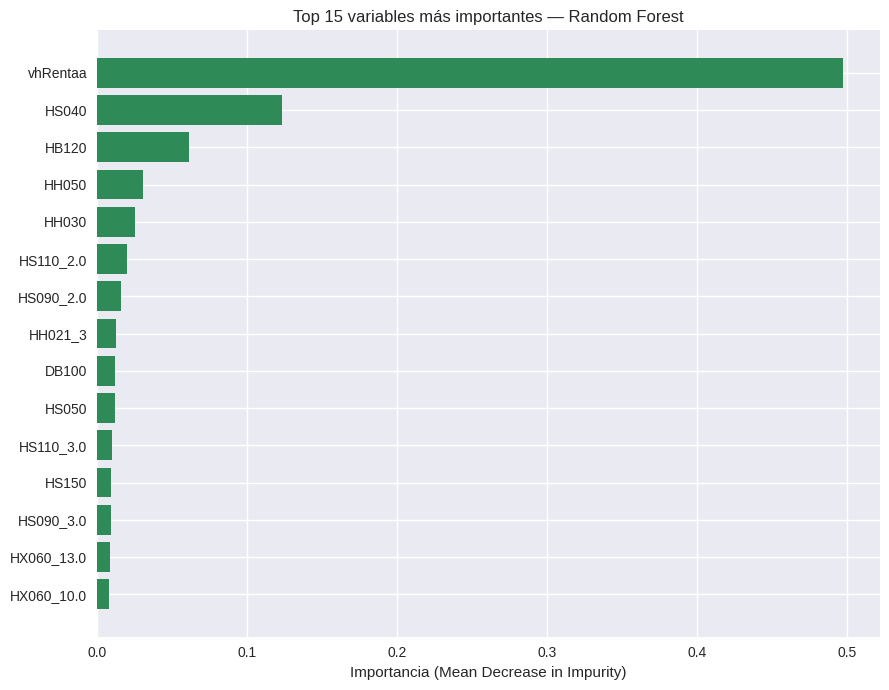


Peso de vhRentaa: 49.7% del total de importancia del modelo


In [ ]:
# ============================================================
# 9.1 FEATURE IMPORTANCE — RANDOM FOREST
# ============================================================

importancias = pd.DataFrame({
    'variable': nombres_finales,
    'importancia': rf.feature_importances_
}).sort_values('importancia', ascending=False)

print("TOP 15 VARIABLES MÁS IMPORTANTES (Random Forest)")
print("="*55)
print(importancias.head(15).to_string(index=False))

# Gráfico
fig, ax = plt.subplots(figsize=(9, 7))
top15 = importancias.head(15).sort_values('importancia')
ax.barh(top15['variable'], top15['importancia'], color='seagreen')
ax.set_xlabel('Importancia (Mean Decrease in Impurity)')
ax.set_title('Top 15 variables más importantes — Random Forest')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/datos_2025/processed/feature_importance_rf.png', dpi=150)
plt.show()

# % de importancia acumulada de vhRentaa vs. resto (para la discusión del apartado 9.1)
peso_renta = importancias[importancias['variable'] == 'vhRentaa']['importancia'].values[0]
print(f"\nPeso de vhRentaa: {peso_renta*100:.1f}% del total de importancia del modelo")

El análisis de importancia de variables del Random Forest confirma el patrón
observado en el resto del trabajo: la renta disponible del hogar (vhRentaa) es,
con diferencia, el predictor más influyente, concentrando el 49,7% de la
importancia total del modelo. La capacidad de permitirse unas vacaciones (HS040)
es la segunda variable más relevante (12,3%), seguida del número de miembros del
hogar (HB120, 6,1%).

Un resultado especialmente valioso surge de la codificación nominal aplicada a
las variables de disponibilidad de ordenador y vehículo (HS090, HS110): el
análisis distingue por separado la contribución de cada categoría, revelando
que la carencia por motivos económicos («no puede permitírselo») aporta
aproximadamente el doble de importancia predictiva que la carencia por otros
motivos, tanto en HS110 (2,0% frente a 1,0%) como en HS090 (1,6% frente a
0,9%). Este resultado confirma que no tratar estas variables como una escala ordinal simple estaba justificada: ambas categorías de "no" no son equivalentes de cara a la predicción de vulnerabilidad.

El resto del top 15 recoge indicadores adicionales de privación material
(temperatura adecuada, número de habitaciones), régimen de tenencia (alquiler
a precio de mercado) y composición del hogar (hogares con hijos dependientes),
confirmando que el modelo capta indicadores genuinos de exclusión financiera más
allá de la renta.

Aunque el modelo principal seleccionado es Random Forest (apartado 8.3), se analizan también los coeficientes de la Regresión Logística por su valor interpretativo directo y como contraste metodológico.

In [ ]:
# ============================================================
# 9.2 COEFICIENTES — REGRESIÓN LOGÍSTICA (ODDS RATIOS)
# ============================================================

coeficientes = pd.DataFrame({
    'variable': nombres_finales,
    'coeficiente': log_reg.coef_[0]
})
coeficientes['odds_ratio'] = np.exp(coeficientes['coeficiente'])
coeficientes = coeficientes.sort_values('coeficiente', ascending=False)

print("VARIABLES QUE MÁS AUMENTAN EL RIESGO (top 10)")
print("="*55)
print(coeficientes.head(10).to_string(index=False))

print("\nVARIABLES QUE MÁS REDUCEN EL RIESGO (top 10)")
print("="*55)
print(coeficientes.tail(10).to_string(index=False))

VARIABLES QUE MÁS AUMENTAN EL RIESGO (top 10)
  variable  coeficiente  odds_ratio
     HB120     2.750219   15.646055
DB040_ES63     0.887309    2.428586
DB040_ES64     0.883449    2.419229
     HS040     0.621369    1.861474
DB040_ES42     0.618771    1.856645
DB040_ES70     0.605064    1.831369
 HS110_2.0     0.587743    1.799921
DB040_ES62     0.496554    1.643049
HX060_14.0     0.483182    1.621225
 HS090_2.0     0.446755    1.563231

VARIABLES QUE MÁS REDUCEN EL RIESGO (top 10)
  variable  coeficiente  odds_ratio
DB040_ES22    -0.237212    0.788824
HX060_10.0    -0.253166    0.776339
DB040_ES21    -0.294158    0.745159
 HX060_8.0    -0.310337    0.733200
 HX060_7.0    -0.385933    0.679816
 HX060_2.0    -0.448750    0.638426
 HX060_6.0    -0.458880    0.631991
 HX060_3.0    -0.586126    0.556479
 HX060_4.0    -0.677639    0.507814
  vhRentaa   -11.711997    0.000008


Antes de mirar los coeficientes, hay que tener en cuenta lo mismo que se mencionó antes: la renta (vhRentaa = -11,72, odds ratio ≈ 0,000008) da
un número tan extremo que no tiene sentido tomarlo al pie de la letra. Esto
pasa porque la renta y la dimensión de pobreza del target están casi
pegadas entre sí matemáticamente, así que el modelo "se dispara" con ese
coeficiente. Lo que sí se puede decir con seguridad es la idea de fondo: a mayor
renta, mucho menor es el riesgo, pero sin tomar la cifra exacta como un
multiplicador real.

Dicho esto, el resto de coeficientes sí se pueden leer con normalidad, y
son coherentes con todo lo demás. El que más destaca es el
número de miembros del hogar (HB120): cuantas más personas viven en la casa,
más sube el riesgo (odds ratio 15,65), esto ya se había observado tanto en los
clusters como en el Random Forest, así que aquí se repite.

Después aparecen varias comunidades autónomas aumentando el riesgo: Ceuta,
Melilla, Castilla-La Mancha, Canarias y Murcia, que son exactamente las
mismas que ya salían como las de mayor riesgo en el mapa territorial. Y al
revés, Navarra y País Vasco aparecen reduciendo el riesgo, que también
coincide con lo que se vio en el mapa. Que dos análisis distintos (los
coeficientes por un lado, los datos reales por otro) cuenten la misma
historia es una buena señal de que el modelo tiene sentido.

También aumenta el riesgo el hecho de no poder permitirse vacaciones (HS040) y no tener coche u ordenador por no poder pagarlo (HS110 y HS090, siempre la categoría de "no puede permitírselo", no la de "otro motivo"), y los hogares con
hijos a cargo de composición menos habitual. En cambio, casi todos los
hogares de una sola persona (viva quien viva: hombres o mujeres, jóvenes o
mayores) aparecen reduciendo el riesgo. Esto no es del todo extraño, pues el
INE calcula la pobreza ajustando por el tamaño del hogar, así que una persona
sola necesita, en proporción, menos dinero total para no estar en riesgo de
pobreza que una familia de varios miembros.

10. Visualización territorial de resultados

RIESGO DE VULNERABILIDAD POR COMUNIDAD AUTÓNOMA
                    n_hogares  vulnerabilidad_real  riesgo_medio_predicho
CCAA                                                                     
Melilla                   187                 25.1                   25.7
Ceuta                     209                 23.9                   23.1
Extremadura              1079                 18.2                   21.7
Andalucía                3206                 19.0                   21.1
Murcia                   1173                 18.1                   20.2
Canarias                 1059                 17.7                   19.4
Castilla-La Mancha       1200                 16.1                   18.6
C. Valenciana            2308                 15.0                   17.7
Galicia                  1630                 12.1                   16.3
Asturias                 1051                 10.9                   13.6
Castilla y León          1662                 10.2              

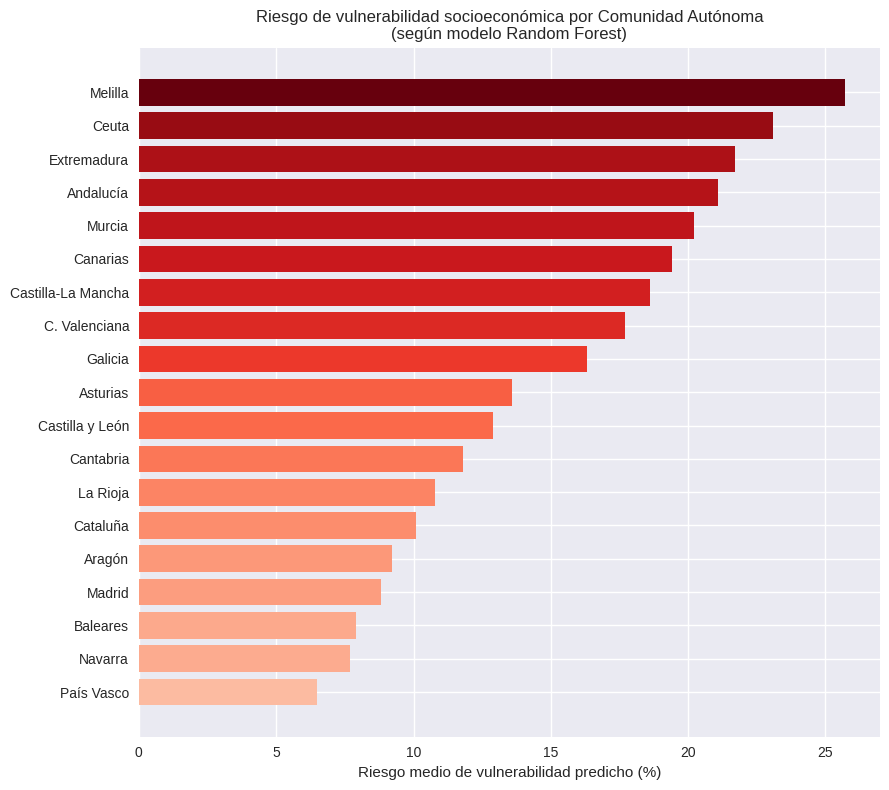

In [ ]:
# ============================================================
# 10.1. RIESGO DE VULNERABILIDAD POR COMUNIDAD AUTÓNOMA
# ============================================================

# Probabilidad predicha de vulnerabilidad para TODOS los hogares,
# usando el modelo final (Random Forest) sobre el dataset completo
proba_vulnerable = rf.predict_proba(X_completo_prep)[:, 1]

# Dataframe territorial: predicción del modelo vs. vulnerabilidad real, por CCAA
df_territorial = X.copy()
df_territorial['CCAA'] = df_final.loc[X.index, 'CCAA_nombre']
df_territorial['prob_predicha'] = proba_vulnerable
df_territorial['vulnerable_real'] = y.values

resumen_ccaa = df_territorial.groupby('CCAA').agg(
    n_hogares=('vulnerable_real', 'size'),
    vulnerabilidad_real=('vulnerable_real', 'mean'),
    riesgo_medio_predicho=('prob_predicha', 'mean')
).round(3).sort_values('riesgo_medio_predicho', ascending=False)

resumen_ccaa['vulnerabilidad_real'] *= 100
resumen_ccaa['riesgo_medio_predicho'] *= 100

print("RIESGO DE VULNERABILIDAD POR COMUNIDAD AUTÓNOMA")
print("="*55)
print(resumen_ccaa)

fig, ax = plt.subplots(figsize=(9, 8))
colores = plt.cm.Reds(resumen_ccaa['riesgo_medio_predicho'] / resumen_ccaa['riesgo_medio_predicho'].max())
ax.barh(resumen_ccaa.index, resumen_ccaa['riesgo_medio_predicho'], color=colores)
ax.set_xlabel('Riesgo medio de vulnerabilidad predicho (%)')
ax.set_title('Riesgo de vulnerabilidad socioeconómica por Comunidad Autónoma\n(según modelo Random Forest)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/datos_2025/processed/mapa_ccaa.png', dpi=150)
plt.show()

El mapa confirma lo que ya se observo en el análisis exploratorio: el riesgo se
concentra en el sur y en la periferia (Melilla, Ceuta, Extremadura, Andalucía,
Murcia, Canarias), y es mucho más bajo en el norte y en el centro económico
del país (País Vasco, Navarra, Baleares, Madrid). El orden que da el modelo
casi calca el orden real que hay en los datos, comunidad por comunidad.

Eso sí, las probabilidades que da el modelo salen, en la mayoría de
comunidades, entre 1,5 y 4 puntos por encima de la vulnerabilidad real, esto
pasa por cómo se entrenó el modelo (dándole más peso a los casos vulnerables
para no perdérselos), así que es un efecto esperado, no un fallo. El único
caso raro es Ceuta, donde pasa justo al revés: el modelo predice un poco por
debajo de la realidad, probablemente porque tiene muy pocos hogares en la
muestra (solo 209) y eso hace que cualquier estimación ahí sea menos fiable.

El siguiente mapa complementa la tabla anterior con una visualización geográfica directa del riesgo predicho por Comunidad Autónoma, facilitando la lectura del patrón territorial descrito en la sección 10 del informe.

In [ ]:
# ============================================================
# 10.2.1 MAPA COROPLÉTICO — CARGA DEL GEOJSON
# ============================================================
!pip install -q geopandas

url_geojson = "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/spain-communities.geojson"

try:
    mapa = gpd.read_file(url_geojson)
    print(f"✅ Mapa cargado correctamente: {len(mapa)} regiones")
    print("\nNombres de CCAA en el GeoJSON:")
    print(sorted(mapa['name'].tolist()))
except Exception as e:
    print(f"❌ No se pudo cargar el GeoJSON. Error: {e}")
    print("Si esto falla, avísame con el mensaje de error exacto y buscamos una fuente alternativa.")

✅ Mapa cargado correctamente: 19 regiones

Nombres de CCAA en el GeoJSON:
['Andalucia', 'Aragon', 'Asturias', 'Baleares', 'Canarias', 'Cantabria', 'Castilla-La Mancha', 'Castilla-Leon', 'Cataluña', 'Ceuta', 'Extremadura', 'Galicia', 'La Rioja', 'Madrid', 'Melilla', 'Murcia', 'Navarra', 'Pais Vasco', 'Valencia']


✅ Las 19 CCAA cruzaron correctamente con resumen_ccaa
Valor Canarias: 19.400000000000002 → color RGBA calculado: (np.float64(0.8813379469434832), np.float64(0.1770088427527874), np.float64(0.14925028835063436), np.float64(1.0))


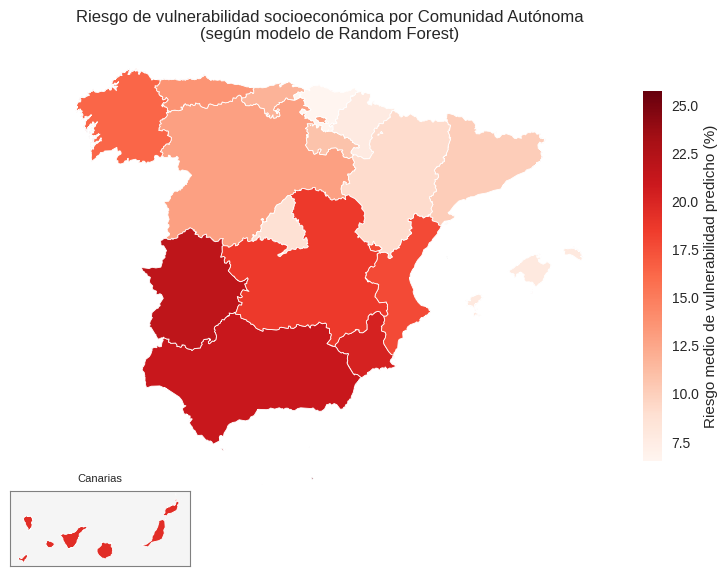

In [ ]:
# ============================================================
# 10.2.2 MAPA COROPLÉTICO REAL — CONSTRUCCIÓN Y VISUALIZACIÓN
# ============================================================
from matplotlib.colors import Normalize

# --- Reconstruimos mapa_datos (por si esta celda se ejecuta de forma aislada) ---
equivalencias = {
    'Andalucia': 'Andalucía', 'Aragon': 'Aragón', 'Asturias': 'Asturias',
    'Baleares': 'Baleares', 'Canarias': 'Canarias', 'Cantabria': 'Cantabria',
    'Castilla-La Mancha': 'Castilla-La Mancha', 'Castilla-Leon': 'Castilla y León',
    'Cataluña': 'Cataluña', 'Ceuta': 'Ceuta', 'Extremadura': 'Extremadura',
    'Galicia': 'Galicia', 'La Rioja': 'La Rioja', 'Madrid': 'Madrid',
    'Melilla': 'Melilla', 'Murcia': 'Murcia', 'Navarra': 'Navarra',
    'Pais Vasco': 'País Vasco', 'Valencia': 'C. Valenciana',
}
mapa['CCAA_match'] = mapa['name'].map(equivalencias)
mapa_datos = mapa.merge(resumen_ccaa, left_on='CCAA_match', right_index=True, how='left')

sin_datos = mapa_datos[mapa_datos['riesgo_medio_predicho'].isna()]['name'].tolist()
if sin_datos:
    print(f"⚠️ CCAA sin datos tras el cruce: {sin_datos}")
else:
    print("✅ Las 19 CCAA cruzaron correctamente con resumen_ccaa")

# --- Gráfico ---
vmin = mapa_datos['riesgo_medio_predicho'].min()
vmax = mapa_datos['riesgo_medio_predicho'].max()
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = plt.colormaps['Reds']

peninsula = mapa_datos[mapa_datos['name'] != 'Canarias']
canarias = mapa_datos[mapa_datos['name'] == 'Canarias']

fig, ax = plt.subplots(figsize=(9, 8))
peninsula.plot(
    column='riesgo_medio_predicho', cmap='Reds', linewidth=0.6,
    edgecolor='white', legend=True, ax=ax, norm=norm,
    legend_kwds={'label': 'Riesgo medio de vulnerabilidad predicho (%)', 'shrink': 0.6}
)
ax.set_title('Riesgo de vulnerabilidad socioeconómica por Comunidad Autónoma\n(según modelo de Random Forest)', fontsize=12)
ax.set_axis_off()

valor_canarias = canarias['riesgo_medio_predicho'].values[0]
color_canarias = cmap(norm(valor_canarias))
print(f"Valor Canarias: {valor_canarias} → color RGBA calculado: {color_canarias}")

ax_ins = fig.add_axes([0.08, 0.08, 0.20, 0.20])
ax_ins.set_facecolor('#f5f5f5')
for spine in ax_ins.spines.values():
    spine.set_edgecolor('gray')
    spine.set_linewidth(0.8)
canarias.plot(color=color_canarias, edgecolor='white', linewidth=0.6, ax=ax_ins)
ax_ins.set_xticks([])
ax_ins.set_yticks([])
ax_ins.set_title('Canarias', fontsize=8)

plt.savefig('/content/drive/MyDrive/TFM/datos_2025/processed/mapa_ccaa_real.png', dpi=150, bbox_inches='tight')
plt.show()

11. Productivización del modelo

In [ ]:
# ============================================================
# 11.3 EXPLICABILIDAD INDIVIDUAL — SHAP (sobre Random Forest)
# ============================================================
!pip install -q shap
import shap

# TreeExplainer es la opción estándar para modelos de árboles: es exacto
# y no necesita una muestra de referencia como el explicador lineal
explainer_shap = shap.TreeExplainer(rf)
print("✅ Explainer SHAP creado sobre Random Forest")

✅ Explainer SHAP creado sobre Random Forest


In [ ]:
# ============================================================
# 11.3 EXPLICABILIDAD INDIVIDUAL (SHAP) — FUNCIONES DE VISUALIZACIÓN
# ============================================================

nombres_legibles = {
    'vhRentaa': 'Renta disponible', 'HH030': 'Número de habitaciones',
    'HB120': 'Número de miembros', 'DB100': 'Grado de urbanización',
    'HS040': 'Puede permitirse vacaciones', 'HS050': 'Puede permitirse proteína',
    'HH050': 'Temperatura adecuada', 'HS090': 'Dispone de ordenador',
    'HS110': 'Dispone de vehículo', 'HS150': 'Carga financiera de deudas',
}

def nombre_bonito(col):
    if col in nombres_legibles:
        return nombres_legibles[col]
    if col.startswith('DB040_'):
        codigo_nuts = col.replace('DB040_', '')
        nombre = ccaa_nombres.get(codigo_nuts, codigo_nuts)  # si no lo encuentra, deja el código tal cual
        return f"CCAA: {nombre}"
    if col.startswith('HH010_'): return "Tipo de vivienda"
    if col.startswith('HH021_'): return "Régimen de tenencia"
    if col.startswith('HX060_'): return "Tipo de hogar"
    return col

def explicar_prediccion(fila_prep):
    fila_densa = fila_prep.toarray() if hasattr(fila_prep, 'toarray') else fila_prep
    shap_values_todas_clases = explainer_shap.shap_values(fila_densa)
    # Forma (1, 50, 2): nos quedamos con la fila 0 y la clase 1 (vulnerable)
    shap_values = shap_values_todas_clases[0, :, 1]

    contribuciones = pd.DataFrame({
        'variable': [nombre_bonito(c) for c in nombres_finales],
        'shap': shap_values
    })
    top = contribuciones.reindex(contribuciones['shap'].abs().sort_values(ascending=False).index).head(6)
    top = top.sort_values('shap')

    colores = ['#C2410C' if v > 0 else '#0F766E' for v in top['shap']]
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.barh(top['variable'], top['shap'], color=colores)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Contribución al riesgo (naranja = aumenta, verde = reduce)')
    ax.set_title('¿Qué factores más influyen en esta predicción?')
    plt.tight_layout()
    return fig

In [ ]:
# ============================================================
# 11.1 DESARROLLO DE LA APLICACIÓN — FUNCIÓN PREDICTIVA
# ============================================================
from scipy.stats import percentileofscore

tipo_vivienda_label = {
    1: "Vivienda unifamiliar independiente",
    2: "Vivienda unifamiliar adosada o pareada",
    3: "Piso o apartamento en edificio con menos de 10 viviendas",
    4: "Piso o apartamento en edificio con 10 viviendas o más",
}

tipo_hogar_label = {
    1: "Persona sola: hombre menor de 30 años",
    2: "Persona sola: hombre de 30 a 64 años",
    3: "Persona sola: hombre de 65 o más años",
    4: "Persona sola: mujer menor de 30 años",
    5: "Persona sola: mujer de 30 a 64 años",
    6: "Persona sola: mujer de 65 o más años",
    7: "2 adultos sin hijos, uno de 65 años o más",
    8: "2 adultos sin hijos, ambos menores de 65 años",
    9: "Otros hogares sin hijos dependientes",
    10: "1 adulto con al menos 1 hijo dependiente",
    11: "2 adultos con 1 hijo dependiente",
    12: "2 adultos con 2 hijos dependientes",
    13: "2 adultos con 3 o más hijos dependientes",
    14: "Otros hogares con hijos dependientes",
}

def clasificar_riesgo(prob_nueva):
    percentil = percentileofscore(proba_vulnerable, prob_nueva)
    if percentil < 33:
        return "🟢 Bajo", percentil
    elif percentil < 66:
        return "🟡 Medio", percentil
    else:
        return "🔴 Alto", percentil

def predecir_vulnerabilidad(
    ccaa, urbanizacion, renta, carga_deuda, vacaciones, comida,
    temperatura, ordenador, coche, tipo_vivienda, tenencia,
    n_habitaciones, n_miembros, tipo_hogar
):
    fila = pd.DataFrame([{
        'DB040': {v: k for k, v in ccaa_nombres.items()}[ccaa],
        'DB100': {v: k for k, v in urb_labels.items()}[urbanizacion],
        'vhRentaa': renta,
        'HS150': carga_deuda,
        'HS040': 1 if vacaciones == "Sí" else 2,
        'HS050': 1 if comida == "Sí" else 2,
        'HH050': 1 if temperatura == "Sí" else 2,
        'HS090': {"Sí": 1, "No, no puede permitírselo": 2, "No, por otro motivo": 3}[ordenador],
        'HS110': {"Sí": 1, "No, no puede permitírselo": 2, "No, por otro motivo": 3}[coche],
        'HH010': {v: k for k, v in tipo_vivienda_label.items()}[tipo_vivienda],
        'HH021': {v: k for k, v in ten_labels.items()}[tenencia],
        'HH030': n_habitaciones,
        'HB120': n_miembros,
        'HX060': {v: k for k, v in tipo_hogar_label.items()}[tipo_hogar],
    }])

    fila = fila[X.columns]
    fila_prep = preprocesador.transform(fila)

    prob = rf.predict_proba(fila_prep)[0, 1]
    categoria, percentil = clasificar_riesgo(prob)
    grafico = explicar_prediccion(fila_prep)

    resultado = f"""
### Resultado de la evaluación

**Categoría de riesgo:** {categoria}

**Probabilidad estimada por el modelo:** {prob*100:.1f}%

**Posición relativa:** este hogar presenta mayor riesgo que el {percentil:.0f}% de los hogares españoles analizados.

---
⚠️ *Nota metodológica: el modelo se entrenó con un ajuste de pesos de clase para mejorar la detección de hogares vulnerables. Esto hace que la probabilidad absoluta mostrada esté sistemáticamente por encima del riesgo real observado en los datos (ver sección 10 del informe). Por eso, la **categoría de riesgo y la posición relativa son las referencias más fiables**; la probabilidad se muestra como dato complementario de transparencia del modelo.*
"""
    return resultado, grafico

In [ ]:
# ============================================================
# 11.1 DESARROLLO DE LA APLICACIÓN — INTERFAZ GRADIO
# ============================================================
!pip install -q gradio
import gradio as gr

with gr.Blocks(title="Predicción de Vulnerabilidad Socioeconómica") as demo:
    gr.Markdown("""
    # 🏠 Predictor de Vulnerabilidad Socioeconómica y Exclusión Financiera
    Introduce las características del hogar para estimar su riesgo de ser un
    **hogar doblemente vulnerable** (en riesgo de pobreza y con exclusión financiera).

    *Trabajo de Fin de Máster — UCM · Basado en microdatos ECV 2025 (INE)*
    """)

    with gr.Row():
        with gr.Column():
            ccaa = gr.Dropdown(choices=list(ccaa_nombres.values()), label="Comunidad Autónoma")
            urbanizacion = gr.Dropdown(choices=list(urb_labels.values()), label="Grado de urbanización")
            renta = gr.Slider(0, 100000, value=25000, step=500, label="Renta disponible anual del hogar (€)")
            tenencia = gr.Dropdown(choices=list(ten_labels.values()), label="Régimen de tenencia de la vivienda")
            n_habitaciones = gr.Slider(1, 10, value=4, step=1, label="Número de habitaciones")
            n_miembros = gr.Slider(1, 8, value=3, step=1, label="Número de miembros del hogar")
            carga_deuda = gr.Slider(1, 3, value=3, step=1,
                label="Carga financiera de las deudas (1 = carga pesada, 3 = sin carga / sin deudas)")

        with gr.Column():
            vacaciones = gr.Radio(["Sí", "No"], value="Sí", label="¿Puede permitirse una semana de vacaciones al año?")
            comida = gr.Radio(["Sí", "No"], value="Sí", label="¿Puede permitirse comer proteína cada 2 días?")
            temperatura = gr.Radio(["Sí", "No"], value="Sí", label="¿Puede mantener la vivienda a temperatura adecuada?")
            ordenador = gr.Radio(["Sí", "No, no puede permitírselo", "No, por otro motivo"],value="Sí", label="¿Dispone de ordenador?")
            coche = gr.Radio(["Sí", "No, no puede permitírselo", "No, por otro motivo"], value="Sí", label="¿Dispone de vehículo?")
            tipo_vivienda = gr.Dropdown(choices=list(tipo_vivienda_label.values()), label="Tipo de vivienda")
            tipo_hogar = gr.Dropdown(choices=list(tipo_hogar_label.values()), label="Tipo de hogar")

    boton = gr.Button("🔍 Evaluar riesgo", variant="primary")
    salida = gr.Markdown()
    grafico_salida = gr.Plot(label="Factores que influyen más en esta predicción")

    boton.click(
        fn=predecir_vulnerabilidad,
        inputs=[ccaa, urbanizacion, renta, carga_deuda, vacaciones, comida,
                temperatura, ordenador, coche, tipo_vivienda, tenencia,
                n_habitaciones, n_miembros, tipo_hogar],
        outputs=[salida, grafico_salida]
    )

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://021e833d512758b578.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://021e833d512758b578.gradio.live


In [ ]:
print(f"LR: C={log_reg.C}")
print(f"RF: max_depth={rf.max_depth}, min_samples_leaf={rf.min_samples_leaf}")
print(f"SVM: C={svm.C}, kernel={svm.kernel}")

LR: C=500
RF: max_depth=20, min_samples_leaf=1
SVM: C=100, kernel=linear


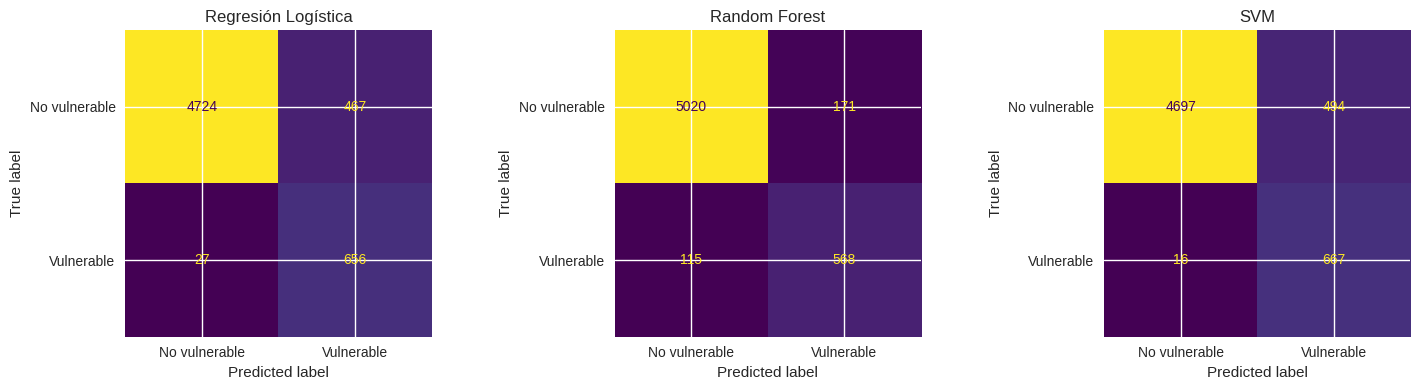

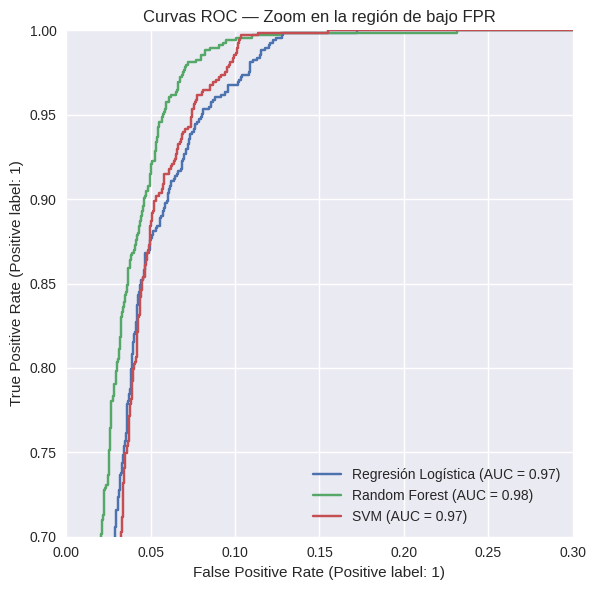

In [ ]:
# ============================================================
# ANEXO C — MATRICES DE CONFUSIÓN Y CURVAS ROC
# ============================================================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

modelos = {'Regresión Logística': log_reg, 'Random Forest': rf, 'SVM': svm}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    y_pred = modelo.predict(X_test_prep)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['No vulnerable', 'Vulnerable']).plot(ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/datos_2025/processed/matrices_confusion.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in modelos.items():
    RocCurveDisplay.from_estimator(modelo, X_test_prep, y_test, ax=ax, name=nombre)
ax.set_xlim(0, 0.3)
ax.set_ylim(0.7, 1.0)
ax.set_title('Curvas ROC — Zoom en la región de bajo FPR')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/TFM/datos_2025/processed/curvas_roc_zoom.png', dpi=150)
plt.show()

In [ ]:
!jupyter nbconvert --to html "/content/drive/MyDrive/TFM/TFM (10).ipynb" --output "/content/drive/MyDrive/TFM/TFM_Lina_Maria_Caro_Perdomo.html"